# Desarrollo 02: lago urbano en China, la primera mejora del algoritmo

El notebook 01 dejo el metodo mas simple que funciono en el ejemplo mas facil, el rio Meguro. Aqui se sigue la regla de esta carpeta: **se copia ese notebook cambiando solo la configuracion, se mira que falla, y se cambia solo lo que el fallo obliga**, con **los mismos valores en las dos camaras**.

**Resultado.** En las 5 secciones (234 fotos, 173 con lectura manual), **la v2 da un error absoluto medio de 4.12 cm y 61.7 % en +-2 cm**, frente a 18.24 cm y 9 % de la copia sin cambios. En la **serie completa, la v2 da 2.91 cm, 73.6 % en +-2 cm y 80.2 % en +-5 cm** (2680 fotos). Se estima con la referencia una constante de cero. **En Meguro, con los mismos valores, mejora:** 0.87 cm y 96 % en +-2 cm, frente a 1.11 cm y 92 %. En China falla sobre todo de noche, con agua quieta y con agua rizada. No es una prueba del todo a ciegas: seccion 4.2.

**Version anterior.** Una version anterior de este notebook usaba una memoria con umbral: cortaba en el primer tramo de 1 cm por debajo del 70 % del parecido de la parte seca. En China daba 0.57 cm en la serie completa, pero con los mismos valores empeoraba Meguro (1.49 cm), asi que quedaba como una opcion por camara. Esta guardada en `anteriores/`, y el notebook 03 se construyo sobre ella.

| Parte | |
|---|---|
| 1. Copia del notebook 01 | mismo codigo, solo cambia la configuracion. Tabla de valores Meguro / China |
| 2. Problemas | que salio mal, con figuras y su causa, y que no dio problema |
| 3. Cambios al codigo | cada cambio con su fallo y su diff literal; lista de lineas comprobada contra el notebook 01 |
| 4. Resultados en China | por seccion, v1 y v2 (tabla principal), serie completa aparte, video |
| 5. Comprobacion en Meguro | el mismo codigo v2, con los mismos valores, en las 53 fotos del ejemplo 1, foto por foto |
| 6. Limitaciones | que queda sin resolver |

**De donde sale cada numero.** Las partes 1 a 3 y la tabla principal se calculan solo sobre **5 secciones** de la serie (234 fotos). La **serie completa** (3315 fotos) es una validacion final de la v2 y se da aparte, en la seccion 4.3.

# 1. Copia del notebook 01

## 1.1 Preparacion y datos

**Datos.** [Zenodo 10812125](https://zenodo.org/records/10812125), CC BY 4.0: 3315 fotos de 3840 x 2160 px de una camara fija sobre la mira de un lago urbano del sur de China, una cada 15 min, del 27-may al 6-jul-2023; de noche la camara pasa a infrarrojo. La lectura manual de 2691 fotos es la referencia, y **solo se abre en la seccion 4.2**.

**Las secciones.** Son bloques continuos de la serie, sin quitar ninguna foto de dentro. **Se eligieron solo mirando las imagenes**, en hojas con varias fotos de cada dia, y con una regla fijada antes de medir:

| Seccion | Bloque | Como se eligio |
|---|---|---|
| dia, agua quieta | 27-may 06:00 a 17:30 | agua quieta y reflejo claro: el primer dia de la serie |
| dia, agua rizada | 11-jun 09:30 a 16:00 | el primer bloque de dia de unas 6 h en que no se ve reflejo |
| noche | 27-may 20:00 a 28-may 05:00 | infrarrojo: la primera noche completa |
| cambio brusco | 4-jul 11:00 a 20:00 | el agua sube ~17 cm en menos de dos horas, con lluvia; es la mayor crecida visible |
| vaciado | 19-jun, todo el dia | el agua mas baja de la serie; incluye la foto seca de la seccion 3 |

**Cautela sobre la eleccion.** La referencia no se habia abierto al fijarlas. Si se conocia, de pruebas sin referencia, que el metodo falla en parte de las fotos de finales de mayo; por eso se uso la regla "el primero" y no un dia elegido a mano, y ese dia queda dentro.

Con `SOLO_SECCIONES = True` el notebook corre en pocos minutos y lee la serie completa de un CSV guardado; con `False` la vuelve a medir.

In [1]:
import ast
import difflib
import json
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

sys.path.insert(0, os.path.join("..", "..", "herramientas"))
import escritor_video                     # escribe H.264 por una tuberia a ffmpeg (cv2.VideoWriter no sirve aqui)

plt.rcParams.update({"figure.dpi": 90, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.labelcolor": "#52514e"})

# Colores de las figuras: rojo = linea de agua, azul = ventanas, amarillo = marcas y lectura a ojo
ROJO, AZUL, NARANJA, AMARILLO = "#e34948", "#2a78d6", "#eb6834", "#eda100"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

SOLO_SECCIONES = True     # True: solo las secciones, la serie completa se lee del CSV guardado. False: se vuelve a medir la serie completa

DATOS = os.path.join("..", "..", "01_zenodo_lago_china", "datos", "SAM_water_level_Dataset")
CARPETA_FOTOS = os.path.join(DATOS, "Staff gauge images")
EXCEL_REFERENCIA = os.path.join(DATOS, "In-situ water levels", "In-situ & simulated water levels.xlsx")   # solo se abre en la seccion 4.2
SALIDAS = "salidas"
os.makedirs(SALIDAS, exist_ok=True)

TEXTO_NIVEL = (0, 0, 0, 0)                # x0, y0, x1, y1: en este ejemplo no hay nivel impreso que tapar


def leer(archivo):
    img = cv2.imread(os.path.join(CARPETA_FOTOS, archivo))
    x0, y0, x1, y1 = TEXTO_NIVEL
    img[y0:y1, x0:x1] = 0
    return img


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def gris(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def hora_de(archivo):
    # P23052700112410.jpg -> 2023-05-27 00:11:24 (hora local que imprime la camara)
    return datetime.strptime(os.path.basename(archivo)[1:13], "%y%m%d%H%M%S")


fotos = sorted(os.path.relpath(os.path.join(r, f), CARPETA_FOTOS).replace("\\", "/")
               for r, _, fs in os.walk(CARPETA_FOTOS) for f in fs if f.endswith(".jpg"))
print("%d fotos, de %s a %s" % (len(fotos), hora_de(fotos[0]), hora_de(fotos[-1])))

# >>> AJUSTABLE <<< las secciones: bloques continuos, elegidos solo con la imagen
SECCIONES = {"dia, agua quieta": ("2023-05-27 06:00", "2023-05-27 17:30"),
             "dia, agua rizada": ("2023-06-11 09:30", "2023-06-11 16:00"),
             "noche": ("2023-05-27 20:00", "2023-05-28 05:00"),
             "cambio brusco": ("2023-07-04 11:00", "2023-07-04 20:00"),
             "vaciado": ("2023-06-19 00:00", "2023-06-19 23:59")}


def seccion_de(archivo):
    h = hora_de(archivo)
    for nombre, (t0, t1) in SECCIONES.items():
        if pd.Timestamp(t0) <= h <= pd.Timestamp(t1):
            return nombre
    return None


fotos_s = [a for a in fotos if seccion_de(a) is not None]
print("En las secciones: %d fotos" % len(fotos_s), {s: sum(seccion_de(a) == s for a in fotos_s) for s in SECCIONES})

3315 fotos, de 2023-05-27 00:11:24 a 2023-07-06 10:56:17
En las secciones: 234 fotos {'dia, agua quieta': 46, 'dia, agua rizada': 26, 'noche': 36, 'cambio brusco': 36, 'vaciado': 90}


## 1.2 Una foto

La mira tiene un numero cada 10 cm y una marca en E cada 2 cm. Debajo de la linea de agua se ve su reflejo.

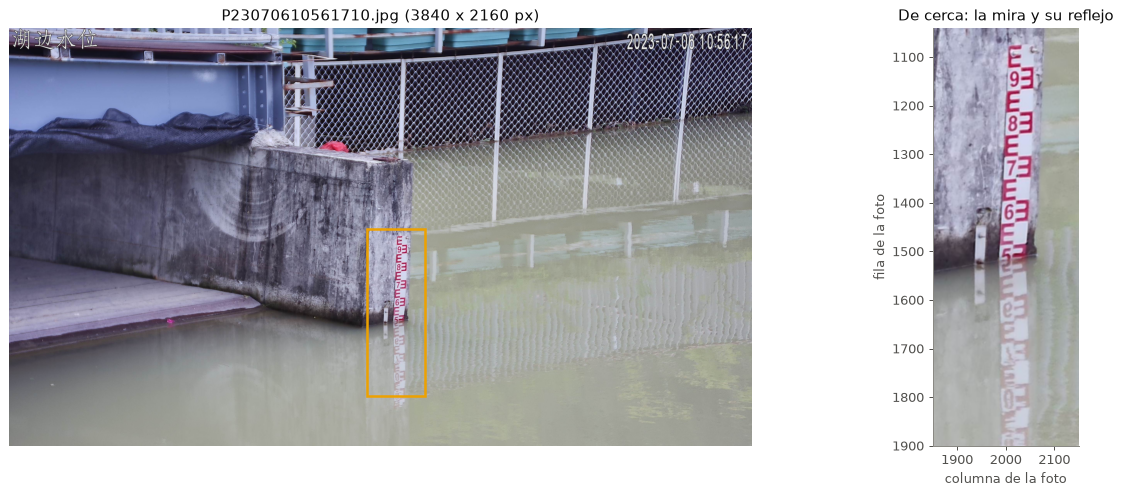

In [2]:
FOTO = "20230706/images/P23070610561710.jpg"     # la foto con la que se explica el metodo
img = leer(FOTO)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [2.6, 1]})
ax[0].imshow(rgb(img)); ax[0].axis("off")
ax[0].set_title("%s (%d x %d px)" % (os.path.basename(FOTO), img.shape[1], img.shape[0]), color=TINTA)
ax[0].add_patch(Rectangle((1850, 1040), 300, 860, fill=False, ec=AMARILLO, lw=2))
ax[1].imshow(rgb(img[1040:1900, 1850:2150]), extent=[1850, 2150, 1900, 1040], interpolation="bicubic")
ax[1].set_title("De cerca: la mira y su reflejo", color=TINTA)
ax[1].set_xlabel("columna de la foto"); ax[1].set_ylabel("fila de la foto")
plt.tight_layout()

## 1.3 Configuracion: cuatro puntos y dos niveles

Igual que en el notebook 01: a mano, una vez, sobre la foto de agua mas baja. Son los bordes de la mira y dos marcas conocidas: 95 y 25 cm.

Esquinas: sup_izq (2005.3, 1119.5), sup_der (2059.4, 1119.5), inf_der (2032.2, 1762.0), inf_izq (1979.2, 1762.0)


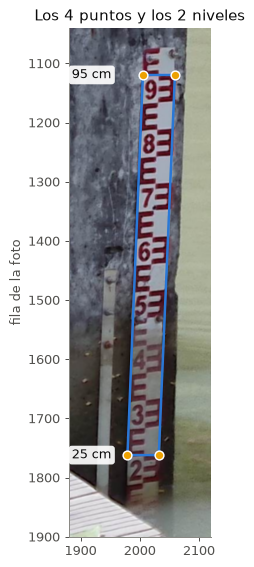

In [3]:
# >>> AJUSTABLE <<< (x, fila) de cada borde de la placa, leidos a ojo sobre ampliaciones de la foto de agua mas baja
BORDE_IZQ = [(2002, 1200), (1980, 1742)]
BORDE_DER = [(2056, 1200), (2033, 1742)]

# >>> AJUSTABLE <<< dos niveles conocidos (cm de mira) y la fila donde estan, leidos a ojo
NIVEL_SUP, FILA_SUP = 95.0, 1119.5        # marca de 95 cm
NIVEL_INF, FILA_INF = 25.0, 1762.0        # marca de 25 cm


def recta_por(puntos):
    (xa, ya), (xb, yb) = puntos
    return lambda y: xa + (np.asarray(y, float) - ya) * (xb - xa) / (yb - ya)


x_izq, x_der = recta_por(BORDE_IZQ), recta_por(BORDE_DER)
SUP_IZQ, SUP_DER = (float(x_izq(FILA_SUP)), FILA_SUP), (float(x_der(FILA_SUP)), FILA_SUP)
INF_DER, INF_IZQ = (float(x_der(FILA_INF)), FILA_INF), (float(x_izq(FILA_INF)), FILA_INF)
print("Esquinas: sup_izq (%.1f, %.1f), sup_der (%.1f, %.1f), inf_der (%.1f, %.1f), inf_izq (%.1f, %.1f)"
      % (*SUP_IZQ, *SUP_DER, *INF_DER, *INF_IZQ))

ref = leer("20230619/images/P23061910562010.jpg")       # la foto de agua mas baja
fig, a0 = plt.subplots(figsize=(4.4, 6.4))
a0.imshow(rgb(ref[1040:1900, 1880:2120]), extent=[1880, 2120, 1900, 1040], interpolation="bicubic")
a0.add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
for (x, y), texto in [(SUP_IZQ, "95 cm"), (INF_IZQ, "25 cm")]:
    a0.plot([x, x + (SUP_DER[0] - SUP_IZQ[0])], [y, y], "o", ms=7, mfc=AMARILLO, mec="white", mew=1.2)
    a0.text(1885, y, texto, color=TINTA, va="center", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.92))
a0.set_title("Los 4 puntos y los 2 niveles", color=TINTA); a0.set_ylabel("fila de la foto")
plt.tight_layout()

## 1.4 El tablero enderezado

`Tablero` es la clase del notebook 01. Aqui 9 filas son 1 cm, y cada fila vale siempre el mismo nivel.

Tablero de 54 columnas x 900 filas


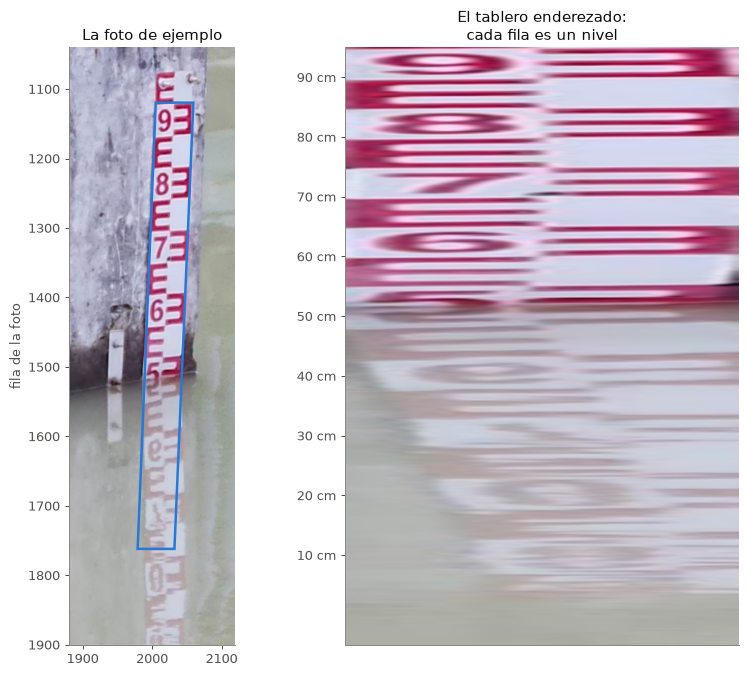

In [4]:
class Tablero:
    # 4 puntos + 2 niveles -> tablero enderezado con lados paralelos: cada fila es un nivel fijo
    def __init__(self, sup_izq, sup_der, inf_der, inf_izq, nivel_sup, nivel_inf, px_por_cm, ancho_px, extra_cm):
        self.nivel_sup, self.px_por_cm = float(nivel_sup), float(px_por_cm)
        alto = (nivel_sup - nivel_inf) * px_por_cm
        src = np.float64([sup_izq, sup_der, inf_der, inf_izq])
        dst = np.float64([[0, 0], [ancho_px, 0], [ancho_px, alto], [0, alto]])
        A = np.hstack([src, np.ones((4, 1))])
        self.M = np.array([np.linalg.lstsq(A, dst[:, i], rcond=None)[0] for i in (0, 1)])   # afin por minimos cuadrados
        self.M_inv = cv2.invertAffineTransform(self.M)
        self.tam = (int(ancho_px), int(alto + extra_cm * px_por_cm))

    def enderezar(self, img):
        return cv2.warpAffine(img, self.M, self.tam, flags=cv2.INTER_LINEAR)

    def fila_de(self, nivel):
        return (self.nivel_sup - nivel) * self.px_por_cm

    def nivel_de(self, fila):
        return self.nivel_sup - fila / self.px_por_cm

    def a_tablero(self, x, y):
        return self.M @ np.array([x, y, 1.0])       # punto de la foto -> (columna, fila) del tablero

    def a_foto(self, col, fila):
        return self.M_inv @ np.array([col, fila, 1.0])   # punto del tablero -> (x, y) de la foto


PX_POR_CM = 9.0        # >>> AJUSTABLE <<< filas del tablero por cm (casi la escala de la camara, 9.2 px/cm)
ANCHO = 54             # >>> AJUSTABLE <<< columnas del tablero (la placa mide unos 54 px de ancho)
EXTRA_CM = 30.0        # >>> AJUSTABLE <<< cm por debajo del nivel inferior, para que entre el reflejo

T = Tablero(SUP_IZQ, SUP_DER, INF_DER, INF_IZQ, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
tablero = T.enderezar(img)
alto_total = T.tam[1]

fig, ax = plt.subplots(1, 2, figsize=(9, 7.6))
ax[0].imshow(rgb(img[1040:1900, 1880:2120]), extent=[1880, 2120, 1900, 1040], interpolation="bicubic")
ax[0].add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
ax[0].set_title("La foto de ejemplo", color=TINTA); ax[0].set_ylabel("fila de la foto")
ax[1].imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
niveles = np.arange(90, 4, -10)
ax[1].set_yticks([T.fila_de(c) for c in niveles]); ax[1].set_yticklabels(["%d cm" % c for c in niveles])
ax[1].set_xticks([]); ax[1].set_title("El tablero enderezado:\ncada fila es un nivel", color=TINTA)
plt.tight_layout()
print("Tablero de %d columnas x %d filas" % T.tam)

## 1.5 Marcas de control

Las marcas de 55 y 45 cm no se usan para enderezar: sirven para comprobar el tablero. Como en el notebook 01, los lados paralelos dan menos error que una homografia de 4 esquinas.

In [5]:
# Fila de la foto de cada marca que no entra en el ajuste, leida a ojo
MARCAS_CONTROL = {55: 1484.0, 45: 1577.0}

fuente = np.float32([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ])
alto_placa = (NIVEL_SUP - NIVEL_INF) * PX_POR_CM
destino = np.float32([[0, 0], [ANCHO, 0], [ANCHO, alto_placa], [0, alto_placa]])
H_libre = cv2.getPerspectiveTransform(fuente, destino)


def fila_homografia(H, x, y):
    return float(cv2.perspectiveTransform(np.float32([[[x, y]]]), H)[0, 0][1])


filas_tabla = []
for c, f in sorted(MARCAS_CONTROL.items()):
    x = float(x_izq(f) + x_der(f)) / 2
    filas_tabla.append({"marca (cm)": c,
                        "lados paralelos: medido - real (cm)": T.nivel_de(T.a_tablero(x, f)[1]) - c,
                        "homografia de 4 esquinas: medido - real (cm)": T.nivel_de(fila_homografia(H_libre, x, f)) - c})
tabla_marcas = pd.DataFrame(filas_tabla).set_index("marca (cm)").round(2)
tabla_marcas

,lados paralelos: medido - real (cm),homografia de 4 esquinas: medido - real (cm)
marca (cm),,
45,0.16,0.47
55,0.29,0.67


## 1.6 El rango de medida

Con el mismo criterio del notebook 01, mirando los extremos de toda la serie: **maximo 78 cm**, porque el 4 de julio el agua llega a ~75 cm y por encima la mira nunca se moja; **minimo 19 cm**, porque en la foto de agua mas baja el agua esta en ~18 cm.

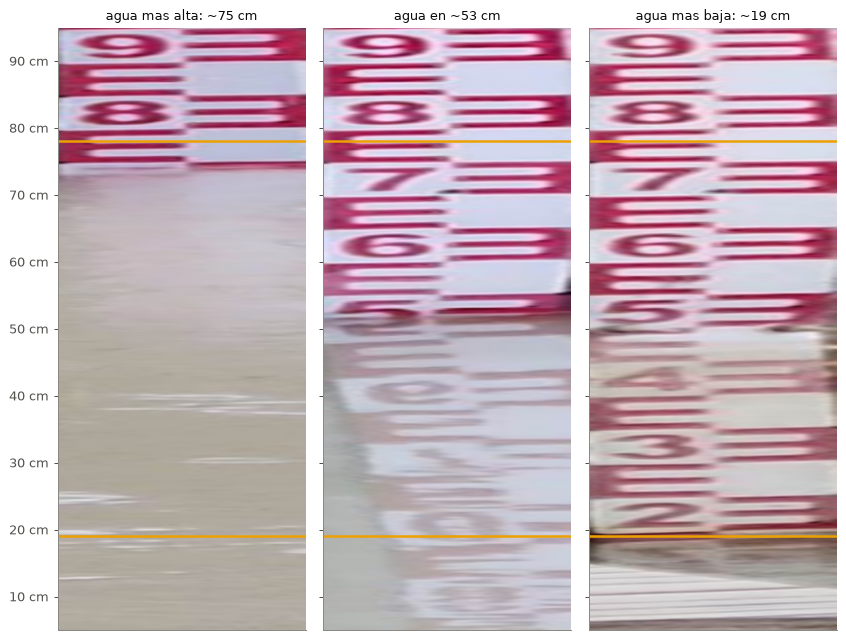

In [6]:
NIVEL_MINIMO = 19.0           # >>> AJUSTABLE <<< cm: en la foto de agua mas baja el agua esta en ~18 cm; por debajo no hay lectura
NIVEL_MAX_AGUA = 78.0         # >>> AJUSTABLE <<< cm: por encima la mira esta siempre seca en esta serie (visto en las fotos)
NIVEL_MIN_BUSQUEDA = 12.0     # >>> AJUSTABLE <<< cm: se busca algo por debajo del minimo para detectar ese caso

fig, ax = plt.subplots(1, 3, figsize=(9.5, 7.2), sharey=True)
for a, archivo, titulo in zip(ax, ["20230704/images/P23070414111910.jpg", FOTO, "20230619/images/P23061911412010.jpg"],
                              ["agua mas alta: ~75 cm", "agua en ~53 cm", "agua mas baja: ~19 cm"]):
    a.imshow(rgb(T.enderezar(leer(archivo))), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
    a.axhline(T.fila_de(NIVEL_MAX_AGUA), color=AMARILLO, lw=2); a.axhline(T.fila_de(NIVEL_MINIMO), color=AMARILLO, lw=2)
    a.set_xticks([]); a.set_title(titulo, fontsize=10, color=TINTA)
ax[0].set_yticks([T.fila_de(c) for c in niveles]); ax[0].set_yticklabels(["%d cm" % c for c in niveles])
ax[0].set_ylim(T.fila_de(5), 0)
plt.tight_layout()

## 1.7 El algoritmo de la linea de agua

Es el del notebook 01, sin tocar una linea. Para cada fila candidata: una **ventana** de 8 cm arriba y otra abajo, se **voltea** la de arriba y se **compara** con correlacion normalizada (NCC); la fila con mas parecido es la **linea de agua**. Solo cambian las columnas, por el ancho de esta mira.

Foto de ejemplo: fila 203 del tablero, 72.4 cm, parecido 0.65. A ojo, el agua esta en ~53 cm.


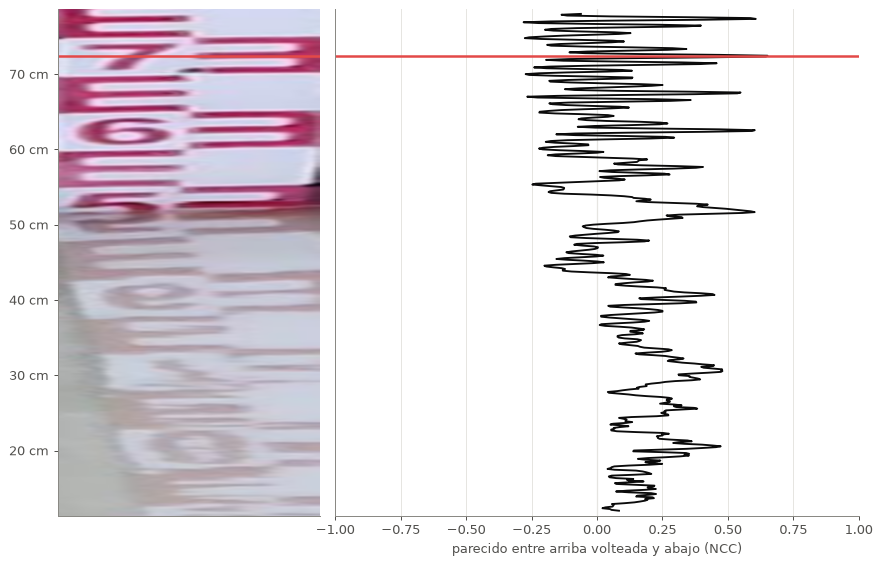

In [7]:
VENTANA_CM = 8.0           # >>> AJUSTABLE <<< alto de cada ventana
H = int(VENTANA_CM * PX_POR_CM)
COLUMNAS = (3, 51)         # >>> AJUSTABLE <<< columnas del tablero que se comparan (dentro de la placa)


def ncc(a, b):
    a = a - a.mean()
    b = b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-9))


def ventanas(R, y, h=H, cols=COLUMNAS):
    # arriba volteada y abajo, listas para comparar
    return R[y - h:y, cols[0]:cols[1]][::-1], R[y:y + h, cols[0]:cols[1]]


def curva_espejo(R, filas, h=H, cols=COLUMNAS):
    return np.array([ncc(*ventanas(R, y, h, cols)) for y in filas])


def espejo(R, nivel_max=NIVEL_MAX_AGUA, nivel_min=NIVEL_MIN_BUSQUEDA, h=H):
    # devuelve la fila del tablero con mas parecido en espejo, su parecido, y la curva entera
    filas = np.arange(max(int(T.fila_de(nivel_max)), h), min(int(T.fila_de(nivel_min)), R.shape[0] - h) + 1)
    s = curva_espejo(R, filas, h)
    k = int(np.argmax(s))
    return int(filas[k]), float(s[k]), filas, s


R = T.enderezar(gris(img))
fila_ej, parecido_ej, filas_ej, curva_ej = espejo(R)
print("Foto de ejemplo: fila %d del tablero, %.1f cm, parecido %.2f. A ojo, el agua esta en ~53 cm." % (fila_ej, T.nivel_de(fila_ej), parecido_ej))

fig, ax = plt.subplots(1, 2, figsize=(10, 6.4), sharey=True, gridspec_kw={"width_ratios": [0.6, 1.2], "wspace": 0.04})
ax[0].imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
ax[0].set_xticks([]); ax[0].set_yticks([T.fila_de(c) for c in niveles]); ax[0].set_yticklabels(["%d cm" % c for c in niveles])
ax[1].plot(curva_ej, filas_ej, color=TINTA, lw=1.5)
ax[1].axvline(0, color=REJILLA, lw=1, zorder=0)
ax[1].grid(axis="x", color=REJILLA, lw=0.8); ax[1].set_axisbelow(True)
for a in ax:
    a.axhline(fila_ej, color=ROJO, lw=2)
ax[1].set_xlim(-1, 1); ax[1].set_xlabel("parecido entre arriba volteada y abajo (NCC)")
ax[1].set_ylim(filas_ej[-1] + 6, filas_ej[0] - 6)
plt.setp(ax[1].get_yticklabels(), visible=False); ax[1].tick_params(axis="y", length=0)
fig.subplots_adjust(left=0.09, right=0.98, top=0.97, bottom=0.09)

## 1.8 De la fila al nivel, y las secciones

`medir_foto` y `marcar_saltos` son las del notebook 01. La conversion es la misma resta: aqui `nivel (cm) = 95 - fila / 9`. Un **salto** es una lectura a mas de 3 cm de la mediana de las 7 fotos que la rodean: es solo un diagnostico, nada se filtra.

Para ver el resultado se usa un **quimograma**: el perfil vertical de la mira de cada foto, uno junto a otro; el tiempo va en horizontal y el nivel en vertical. El agua se ve como el borde donde acaba el dibujo nitido, y los puntos son la lectura. Las noches se aclaran solo para verlas.

,fotos,lee_sobre_62_cm,saltos,parecido_mediano
seccion,,,,
"dia, agua quieta",46,44,2,0.67
noche,36,12,9,0.80
"dia, agua rizada",26,15,8,0.66
vaciado,90,79,12,0.69
cambio brusco,36,20,20,0.68


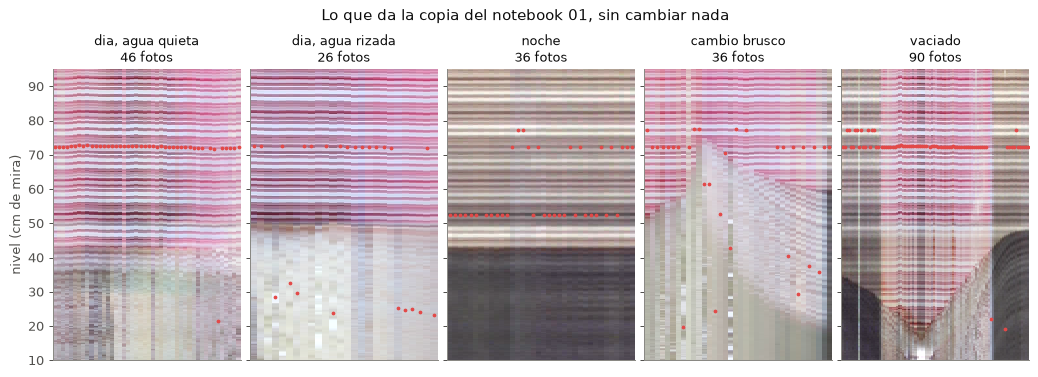

In [8]:
def medir_foto(archivo):
    R = T.enderezar(gris(leer(archivo)))
    fila, parecido, _, _ = espejo(R)
    nivel = T.nivel_de(fila)
    return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
            "fila_foto": float(T.a_foto(ANCHO / 2, fila)[1]), "nivel_bruto_cm": nivel,
            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO)}


SALTO_CM = 3.0     # solo para contar saltos: el metodo basico no filtra nada


def marcar_saltos(serie):
    m = np.array([np.median(serie[max(i - 3, 0):i + 4]) for i in range(len(serie))])
    return np.abs(serie - m) > SALTO_CM


def medir_secciones():
    # recorre las fotos de las secciones, en paralelo, y marca los saltos dentro de cada bloque
    with ThreadPoolExecutor(8) as ex:
        d = pd.DataFrame(list(ex.map(medir_foto, fotos_s))).sort_values("hora").reset_index(drop=True)
    d["seccion"] = [seccion_de(a) for a in d.archivo]
    d["nivel_m"] = np.where(d.bajo_minimo, np.nan, d.nivel_bruto_cm / 100)
    d["salto"] = d.groupby("seccion").nivel_bruto_cm.transform(lambda s: marcar_saltos(s.values)).astype(bool)
    return d


def preparar(archivo):
    c = leer(archivo)
    return archivo, T.enderezar(c)


with ThreadPoolExecutor(8) as ex:
    tiras_s = dict(ex.map(preparar, fotos_s))


def dibujar_secciones(lecturas, titulo=None, alto=4.2):
    # un quimograma por seccion. lecturas: [(dataframe, color, tamano), ...]
    fig, ax = plt.subplots(1, len(SECCIONES), figsize=(14, alto), sharey=True, gridspec_kw={"wspace": 0.05})
    for a, s in zip(ax, SECCIONES):
        lista = [x for x in fotos_s if seccion_de(x) == s]
        cols = []
        for x in lista:
            p = tiras_s[x][:, 8:46].mean(1)
            cols.append(np.clip(p * 230.0 / max(np.percentile(p[:int(T.fila_de(78))], 90), 1), 0, 255))
        K = np.stack(cols, 1).astype(np.uint8)
        a.imshow(K[:, :, ::-1], extent=[0, K.shape[1], T.nivel_de(K.shape[0]), T.nivel_sup], aspect="auto", interpolation="nearest")
        for d, color, ms in lecturas:
            ds = d.set_index("archivo").reindex(lista)
            a.plot(np.arange(len(lista)) + 0.5, ds.nivel_bruto_cm.where(~ds.bajo_minimo.astype(bool)), ".", ms=ms, color=color)
        a.set_ylim(10, 95); a.set_xticks([]); a.set_title("%s\n%d fotos" % (s, len(lista)), fontsize=10, color=TINTA)
    ax[0].set_ylabel("nivel (cm de mira)")
    if titulo:
        fig.suptitle(titulo, color=TINTA, y=1.04)


df_v1 = medir_secciones()
df_v1.to_csv(os.path.join(SALIDAS, "02_v1_secciones.csv"), index=False, float_format="%.4f")
dibujar_secciones([(df_v1, ROJO, 4)], "Lo que da la copia del notebook 01, sin cambiar nada")
df_v1.groupby("seccion", sort=False).agg(fotos=("archivo", "size"), lee_sobre_62_cm=("nivel_bruto_cm", lambda s: int((s > 62).sum())),
                                         saltos=("salto", "sum"), parecido_mediano=("parecido", "median")).round(2)

## 1.9 Que cambio exactamente en esta copia

Se calcula leyendo el codigo de los dos notebooks, no a mano. Primero, los valores de configuracion:

In [9]:
NB_01, NB_02 = os.path.join("..", "01_meguro_algoritmo_basico", "01_meguro_algoritmo_basico.ipynb"), "02_lago_china_primera_mejora.ipynb"


def celdas_codigo(ruta):
    nb = json.load(open(ruta, encoding="utf-8"))
    return ["".join(c["source"]) for c in nb["cells"] if c["cell_type"] == "code"]


def definiciones(ruta):
    # funciones y clases de primer nivel, en orden: [(nombre, codigo), ...]
    salida = []
    for codigo in celdas_codigo(ruta):
        for nodo in ast.parse(codigo).body:
            if isinstance(nodo, (ast.FunctionDef, ast.ClassDef)):
                salida.append((nodo.name, "\n".join(codigo.splitlines()[nodo.lineno - 1:nodo.end_lineno])))
    return salida


def asignaciones(ruta):
    # primer valor escrito para cada nombre en una asignacion de primer nivel: {nombre: texto}
    salida = {}
    for codigo in celdas_codigo(ruta):
        for nodo in ast.parse(codigo).body:
            if isinstance(nodo, ast.Assign) and len(nodo.targets) == 1:
                obj, val = nodo.targets[0], nodo.value
                pares = zip(obj.elts, val.elts) if isinstance(obj, ast.Tuple) and isinstance(val, ast.Tuple) else [(obj, val)]
                for o, v in pares:
                    if isinstance(o, ast.Name):
                        salida.setdefault(o.id, ast.get_source_segment(codigo, v))
    return salida


defs_01, defs_02 = definiciones(NB_01), definiciones(NB_02)
a01, a02 = asignaciones(NB_01), asignaciones(NB_02)
CONFIGURACION = ["DATOS", "CARPETA_FOTOS", "TEXTO_NIVEL", "FOTO", "BORDE_IZQ", "BORDE_DER", "NIVEL_SUP", "FILA_SUP", "NIVEL_INF", "FILA_INF", "PX_POR_CM", "ANCHO",
                 "EXTRA_CM", "MARCAS_CONTROL", "NIVEL_MINIMO", "NIVEL_MAX_AGUA", "NIVEL_MIN_BUSQUEDA", "VENTANA_CM", "COLUMNAS", "H", "SALTO_CM"]
tabla_config = pd.DataFrame([{"valor": n, "Meguro": a01.get(n, "-"), "China": a02.get(n, "-"), "igual": a01.get(n) == a02.get(n)} for n in CONFIGURACION]).set_index("valor")
pd.set_option("display.max_colwidth", 70)
tabla_config

,Meguro,China,igual
valor,,,
DATOS,"os.path.join("".."", ""05_tokio_meguro_suimon"", ""datos"")","os.path.join("".."", ""01_zenodo_lago_china"", ""datos"", ""SAM_water_lev...",False
CARPETA_FOTOS,"os.path.join(DATOS, ""capturas"")","os.path.join(DATOS, ""Staff gauge images"")",False
TEXTO_NIVEL,"(430, 15, 960, 95)","(0, 0, 0, 0)",False
FOTO,"""20261020_142000.jpg""","""20230706/images/P23070610561710.jpg""",False
BORDE_IZQ,"[(647, 160), (650, 510)]","[(2002, 1200), (1980, 1742)]",False
BORDE_DER,"[(705, 160), (707, 510)]","[(2056, 1200), (2033, 1742)]",False
NIVEL_SUP,350.0,95.0,False
FILA_SUP,148.0,1119.5,False
NIVEL_INF,150.0,25.0,False


Y luego el codigo: que funciones son identicas, linea a linea, a las del notebook 01.

In [10]:
primera_01, primera_02 = {}, {}
for n, f in defs_01:
    primera_01.setdefault(n, f)
for n, f in defs_02:
    primera_02.setdefault(n, f)
METODO = ["leer", "rgb", "gris", "recta_por", "Tablero", "fila_homografia", "ncc", "ventanas", "curva_espejo", "espejo", "medir_foto", "marcar_saltos"]
for n in METODO:
    print("%-16s %s" % (n, "identica al notebook 01" if primera_01[n] == primera_02[n] else "DISTINTA"))
print("\nDistinta por el nombre de los archivos, no es del metodo:")
print("\n".join(l for l in difflib.unified_diff(primera_01["hora_de"].splitlines(), primera_02["hora_de"].splitlines(), "notebook 01", "esta copia", lineterm="", n=0)))
assert all(primera_01[n] == primera_02[n] for n in METODO)

leer             identica al notebook 01
rgb              identica al notebook 01
gris             identica al notebook 01
recta_por        identica al notebook 01
Tablero          identica al notebook 01
fila_homografia  identica al notebook 01
ncc              identica al notebook 01
ventanas         identica al notebook 01
curva_espejo     identica al notebook 01
espejo           identica al notebook 01
medir_foto       identica al notebook 01
marcar_saltos    identica al notebook 01

Distinta por el nombre de los archivos, no es del metodo:
--- notebook 01
+++ esta copia
@@ -2,2 +2,2 @@
-    # 20261020_124454.jpg -> 2026-10-20 12:44:54 (hora de Japon en que se pidio el frame)
-    return datetime.strptime(os.path.basename(archivo)[:15], "%Y%m%d_%H%M%S")
+    # P23052700112410.jpg -> 2023-05-27 00:11:24 (hora local que imprime la camara)
+    return datetime.strptime(os.path.basename(archivo)[1:13], "%y%m%d%H%M%S")


**Lo que no es del metodo y si cambia en esta copia:**

- las fotos no se guardan en memoria, porque 4K no caben;
- se recorren en paralelo y por secciones;
- las figuras se adaptan a esta mira;
- se omiten "Lo que no funciono" de Meguro, y la comparacion y el video pasan a la parte 4, porque la referencia solo se abre una vez.

# 2. Problemas

## 2.1 Lo que no da problema

- **La inclinacion.** La mira esta inclinada 2.3 grados, y enderezar ya lo resuelve sin codigo nuevo: el reflejo queda en el mismo plano que la mira. En la figura, las mismas ventanas con y sin enderezar: enderezar no empeora el parecido.
- **La escala.** Hay cinco veces mas detalle que en Meguro y nada cambia: ventanas y rango van en cm.
- **El tablero.** Las marcas de control caen a menos de 0.3 cm (1.5).
- **Las fotos rotas** no paran la serie: siguen dando un numero, y eso si es un problema (2.4).

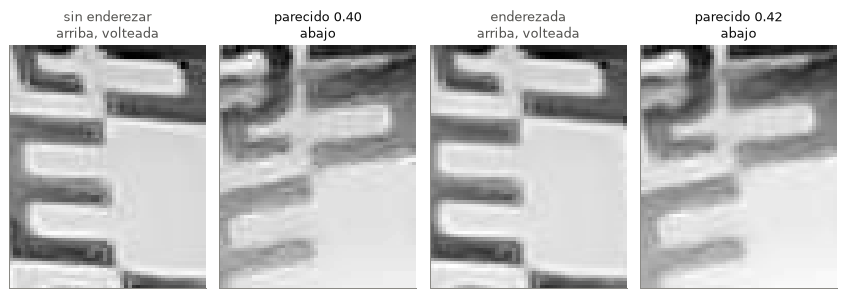

In [11]:
nivel_ojo = 52.6             # la linea de agua de la foto de ejemplo, leida a ojo
fila_t = int(T.fila_de(nivel_ojo))
col_c = ANCHO / 2
x_f, y_f = T.a_foto(col_c, fila_t)
h_f = int(VENTANA_CM * (FILA_INF - FILA_SUP) / (NIVEL_SUP - NIVEL_INF))
x0_f, x1_f, y_f = int(x_f - 24), int(x_f + 24), int(y_f)
gris_img = gris(img)
casos = [("sin enderezar", gris_img[y_f - h_f:y_f, x0_f:x1_f][::-1], gris_img[y_f:y_f + h_f, x0_f:x1_f]), ("enderezada", *ventanas(R, fila_t))]
fig, ax = plt.subplots(1, 4, figsize=(9.5, 3.4))
for i, (nombre, arriba, abajo) in enumerate(casos):
    ax[2 * i].imshow(arriba, cmap="gray", aspect="auto"); ax[2 * i + 1].imshow(abajo, cmap="gray", aspect="auto")
    ax[2 * i].set_title("%s\narriba, volteada" % nombre, fontsize=10, color=TINTA2)
    ax[2 * i + 1].set_title("parecido %.2f\nabajo" % ncc(arriba, abajo), fontsize=10, color=TINTA)
    for a in ax[2 * i:2 * i + 2]:
        a.set_xticks([]); a.set_yticks([])
plt.tight_layout()

## 2.2 Problema 1: el pico cae sobre la mira seca

El 8, el 7, el 6 y las E son simetricos consigo mismos: partidos por la mitad, lo de arriba volteado se parece a lo de abajo, y ademas nitido. El reflejo de verdad es mas palido y esta movido. **Cualquier numero seco le gana al agua.** En Meguro se evitaba buscando solo en el bloque del agua; aqui el agua llega a 75 cm, y en esa zona hay numeros y E. Y al ser un dibujo repetido, limitar mas el rango tampoco serviria.

Buscando en toda la regla: 82.3 cm, parecido 0.77


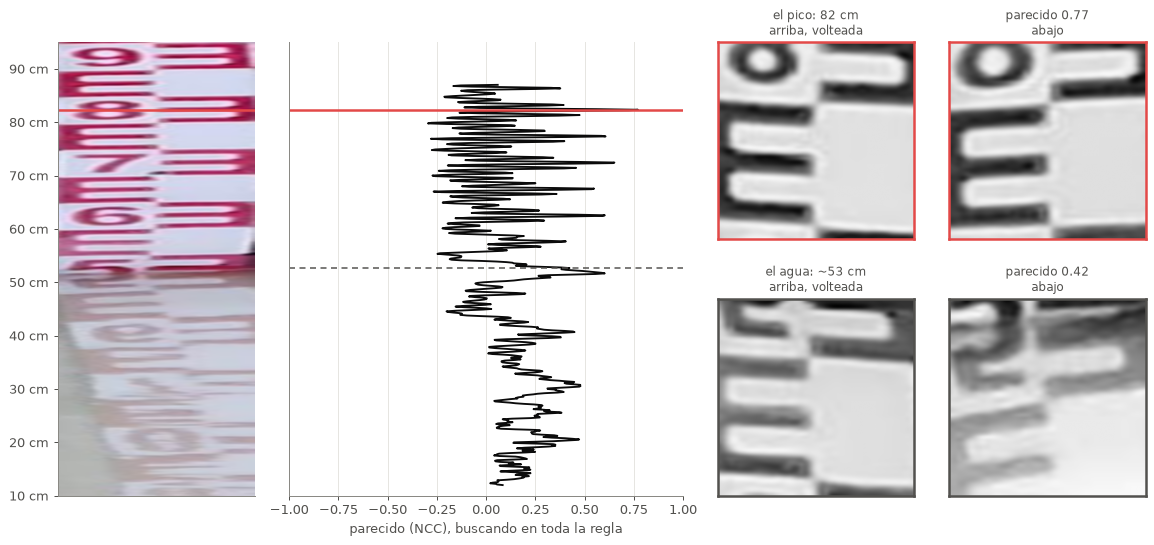

In [12]:
fila_toda, par_toda, filas_toda, curva_toda = espejo(R, nivel_max=NIVEL_SUP)
fig = plt.figure(figsize=(13, 6))
gs = fig.add_gridspec(2, 4, width_ratios=[0.55, 1.1, 0.55, 0.55], wspace=0.14, hspace=0.3)
a0 = fig.add_subplot(gs[:, 0])
a1 = fig.add_subplot(gs[:, 1], sharey=a0)
a0.imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
a0.axhline(fila_toda, color=ROJO, lw=2); a0.set_xticks([])
a0.set_yticks([T.fila_de(c) for c in niveles]); a0.set_yticklabels(["%d cm" % c for c in niveles])
a1.plot(curva_toda, filas_toda, color=TINTA, lw=1.5)
a1.axhline(fila_toda, color=ROJO, lw=2); a1.axhline(fila_t, color=TINTA2, lw=1.2, ls=(0, (4, 3)))
a1.set_xlim(-1, 1); a1.set_xlabel("parecido (NCC), buscando en toda la regla")
a1.grid(axis="x", color=REJILLA, lw=0.8); a1.set_axisbelow(True)
plt.setp(a1.get_yticklabels(), visible=False); a1.tick_params(axis="y", length=0)
a0.set_ylim(T.fila_de(10), T.fila_de(95))
for i, (fila, col, nombre) in enumerate([(fila_toda, ROJO, "el pico: %.0f cm" % T.nivel_de(fila_toda)), (fila_t, TINTA2, "el agua: ~53 cm")]):
    arriba, abajo = ventanas(R, fila)
    for j, (v, t_) in enumerate([(arriba, "arriba, volteada"), (abajo, "abajo")]):
        a = fig.add_subplot(gs[i, j + 2])
        a.imshow(v, cmap="gray", aspect="auto", interpolation="bicubic"); a.set_xticks([]); a.set_yticks([])
        a.set_title("%s\n%s" % (nombre, t_) if j == 0 else "parecido %.2f\n%s" % (ncc(arriba, abajo), t_), fontsize=9.5, color=TINTA2)
        for sp in a.spines.values():
            sp.set_visible(True); sp.set_color(col); sp.set_linewidth(2)
fig.subplots_adjust(left=0.06, right=0.99, top=0.92, bottom=0.08)
print("Buscando en toda la regla: %.1f cm, parecido %.2f" % (T.nivel_de(fila_toda), par_toda))

## 2.3 Problema 2: de noche o sin reflejo, ni siquiera hay espejo

En infrarrojo y con agua rizada el reflejo casi desaparece, y el agua lisa da parecidos sin significado. Estas son fotos de cada seccion, a intervalos regulares: la linea roja es la lectura de la v1.

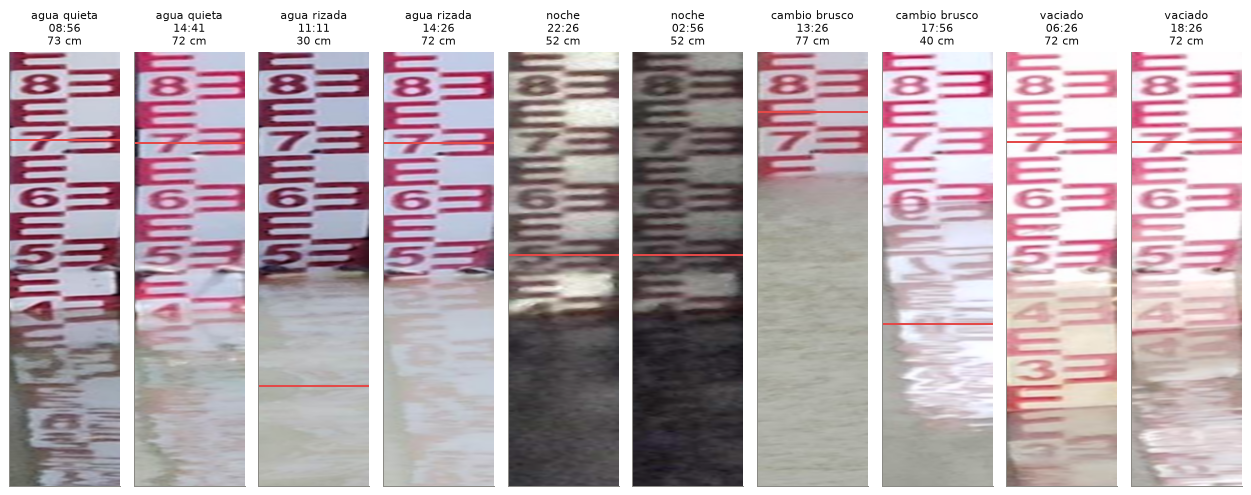

In [13]:
def dibujar_ejemplos(d, color=ROJO, por_seccion=2, titulo=None):
    ejemplos = []
    for s in SECCIONES:
        ds = d[d.seccion == s]
        ejemplos += [ds.iloc[i] for i in np.linspace(len(ds) * 0.25, len(ds) * 0.75, por_seccion).astype(int)]
    fig, ax = plt.subplots(1, len(ejemplos), figsize=(14, 5.6))
    for a, f in zip(ax, ejemplos):
        t = tiras_s[f.archivo]
        if np.percentile(t[:int(T.fila_de(78))], 90) < 140:
            t = np.clip(t.astype(np.float32) * 1.9, 0, 255).astype(np.uint8)
        a.imshow(rgb(t), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
        if np.isfinite(f.nivel_bruto_cm):
            a.axhline(T.fila_de(f.nivel_bruto_cm) + f.get("dy", 0), color=color, lw=1.6)
        a.set_ylim(T.fila_de(12), T.fila_de(88)); a.set_xticks([]); a.set_yticks([])
        a.set_title("%s\n%s\n%.0f cm" % (f.seccion.split(",")[-1].strip(), f.hora.strftime("%H:%M"), f.nivel_bruto_cm), fontsize=8.5, color=TINTA)
    if titulo:
        fig.suptitle(titulo, color=TINTA, y=1.02)
    plt.tight_layout()


dibujar_ejemplos(df_v1)

## 2.4 Problema 3: siempre da un numero

Con una foto rota, la lente empanada o el sol de la tarde quemando la pintura no hay mira que leer, pero la v1 devuelve una lectura igual. Estas fotos estan fuera de las secciones, y se muestran porque en la serie completa existen.

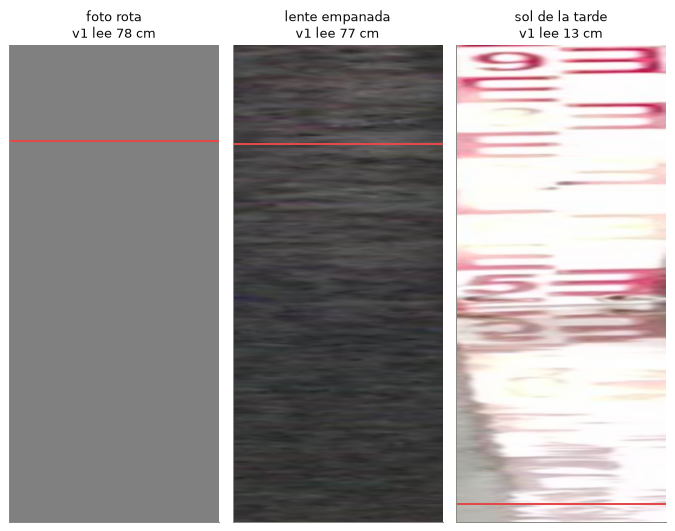

In [14]:
CASOS_MALOS = [("foto rota", "20230530/images/P23053000562110.jpg"), ("lente empanada", "20230609/images/P23060903562410.jpg"), ("sol de la tarde", "20230609/images/P23060918262310.jpg")]
fig, ax = plt.subplots(1, 3, figsize=(7.6, 6))
for a, (nombre, archivo) in zip(ax, CASOS_MALOS):
    c = leer(archivo)
    n_ = T.nivel_de(espejo(T.enderezar(gris(c)))[0])
    a.imshow(rgb(T.enderezar(c)), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
    a.axhline(T.fila_de(n_), color=ROJO, lw=1.6)
    a.set_ylim(T.fila_de(10), 0); a.set_xticks([]); a.set_yticks([])
    a.set_title("%s\nv1 lee %.0f cm" % (nombre, n_), fontsize=10, color=TINTA)
plt.tight_layout()

**Causa comun.** Al metodo le falta un dato que una persona si tiene: **como se ve esa mira cuando esta seca**.

# 3. Cambios al codigo

## Cambios respecto a la version anterior

| # | Que cambia | Por que (fallo) | Seccion |
|---|---|---|---|
| 1 | **Memoria de la mira seca.** Para cada fila candidata se suman dos pistas, cada una llevada a 0..1 dentro de la misma foto: la **separacion** (arriba la mira se parece a una foto seca y abajo no) y el **espejo** de siempre. Gana la fila con la suma mas alta | el pico cae en la mira seca (2.2, 2.3) | 3.1 |
| 2 | **Registro.** Antes de comparar se corrige el movimiento de la camara, con la parte de la mira que nunca se moja | comparar fila a fila falla si la mira se mueve 2 o 3 filas | 3.2 |
| 3 | **Fotos sin lectura.** Si la parte que nunca se moja no se reconoce, no se da nivel | siempre daba un numero (2.4) | 3.3 |

`espejo`, `ncc`, `ventanas`, `curva_espejo`, `Tablero`, `marcar_saltos`, `recta_por`, `leer` y `gris` **no cambian**. La unica funcion que cambia es `medir_foto`, y todo lo demas son funciones nuevas marcadas con `# [v2]`.

**Requisito de esta version: los mismos valores en todas las camaras.** No hay umbrales que ajustar por camara ni una opcion para apagar la memoria: la comprobacion en Meguro (parte 5) usa exactamente estos valores. Lo unico propio de cada camara es su foto seca, elegida con la misma regla (la de agua mas baja). Los valores nuevos son la banda de 2 cm, el margen del registro y el parecido minimo de la parte seca; van en cm o son relativos a la propia foto.

## 3.1 Cambio 1: la memoria de la mira seca

**El fallo.** El pico del espejo cae en la mira seca, porque el metodo no sabe como es.

**Que se agrega.** La foto de agua mas baja se guarda como mira seca. Para cada fila se mide el parecido con la mira seca de una **banda de 2 cm**, con la misma NCC: donde la mira esta seca se parecen, y donde hay agua no. Con eso, cada fila candidata recibe una **separacion**: el parecido medio de las bandas de arriba menos el de las bandas de abajo, pesado por cuantas bandas hay a cada lado (el estadistico de un cambio de nivel), para que unas pocas bandas raras al fondo no ganen. **No se corta en el primer tramo distinto**: se elige la mejor separacion de toda la mira, asi que una sombra o una mancha sueltas no la mueven. La separacion y el espejo se llevan a 0..1 dentro de la foto y se suman con el mismo peso: cuando una pista se engana, la otra no suele enganarse en el mismo sitio.

--- antes
+++ despues
@@ -2,3 +2,3 @@
     R = T.enderezar(gris(leer(archivo)))
-    fila, parecido, _, _ = espejo(R)
+    fila, parecido = elegir_fila(R)                             # [v2]
     nivel = T.nivel_de(fila)


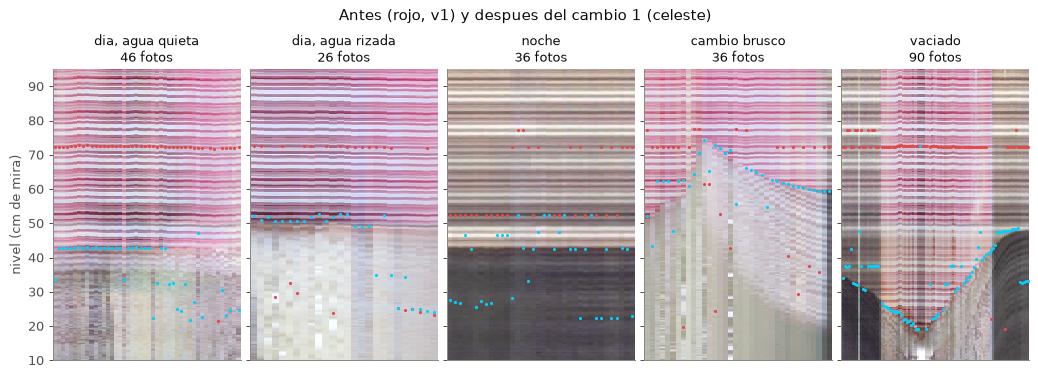

In [15]:
FOTO_SECA = "20230619/images/P23061910562010.jpg"   # >>> AJUSTABLE <<< [v2] la foto de agua mas baja de la camara
BANDA_CM = 2.0            # >>> AJUSTABLE <<< [v2] alto de la banda que se compara con la mira seca
MARGEN_REGISTRO_CM = 2.5  # >>> AJUSTABLE <<< [v2] cuanto se puede mover la mira entre fotos (se usa en 3.2)


def memorizar():
    # [v2] guarda la mira seca y la parte que nunca se moja: por encima del maximo del rango
    global SECA, PATRON, Z0, Z1, MARGEN
    SECA = None if FOTO_SECA is None else T.enderezar(gris(leer(FOTO_SECA)))
    MARGEN = int(MARGEN_REGISTRO_CM * T.px_por_cm)
    Z0, Z1 = MARGEN, int(T.fila_de(NIVEL_MAX_AGUA))
    PATRON = None if SECA is None else SECA[Z0:Z1, COLUMNAS[0]:COLUMNAS[1]]


def parecido_zona_seca(R):
    # [v2] parecido de la parte que nunca se moja con la mira seca. Sin foto seca: 1
    return 1.0 if SECA is None else ncc(R[Z0:Z1, COLUMNAS[0]:COLUMNAS[1]], PATRON)


def parecido_con_seca(R, filas):
    # [v2] NCC, fila a fila, de la banda que empieza en cada fila contra la misma banda de la mira seca
    c0, c1 = COLUMNAS
    hb = int(BANDA_CM * T.px_por_cm)
    return np.array([ncc(R[y:y + hb, c0:c1], SECA[y:y + hb, c0:c1]) for y in filas])


def a_01(v):
    # [v2] lleva un perfil a 0..1 dentro de la misma foto: su fila mas alta vale 1 y la mas baja 0
    r = v.max() - v.min()
    return (v - v.min()) / r if r > 0 else np.zeros_like(v)


def separacion(R, filas):
    # [v2] para cada fila candidata: parecido medio con la mira seca de las bandas de arriba menos el de las de abajo,
    # pesado por cuantas bandas hay a cada lado. El perfil sigue 2 bandas por encima del maximo (siempre seco) y por
    # debajo del fondo del rango, para que toda fila candidata tenga al menos una banda entera a cada lado
    hb = int(BANDA_CM * T.px_por_cm)
    a0 = max(int(T.fila_de(NIVEL_MAX_AGUA)) - 2 * hb, 0)
    a1 = min(int(T.fila_de(NIVEL_MIN_BUSQUEDA)) + 2 * hb, R.shape[0] - hb)
    s = parecido_con_seca(R, np.arange(a0, a1 + 1))
    acum = np.concatenate([[0.0], np.cumsum(s)])
    i = filas - a0                                   # la banda que empieza en cada fila candidata
    na, nb = i - hb + 1, len(s) - i                  # bandas enteras arriba (terminan antes de la fila) y abajo
    arriba, abajo = acum[i - hb + 1] / na, (acum[len(s)] - acum[i]) / nb
    return (arriba - abajo) * np.sqrt(na * nb / (na + nb))


def elegir_fila(R):
    # [v2] suma la separacion y el espejo, cada uno llevado a 0..1; gana la fila con la suma mas alta
    _, _, filas, curva = espejo(R)
    suma = a_01(separacion(R, filas)) + a_01(curva)
    k = int(np.argmax(suma))
    return int(filas[k]), float(curva[k])


def medir_foto(archivo):
    R = T.enderezar(gris(leer(archivo)))
    fila, parecido = elegir_fila(R)                             # [v2]
    nivel = T.nivel_de(fila)
    return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
            "fila_foto": float(T.a_foto(ANCHO / 2, fila)[1]), "nivel_bruto_cm": nivel,
            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO)}


memorizar()
df_c1 = medir_secciones()


def diff_medir_foto(i, j):
    # diff literal entre dos versiones de medir_foto de este notebook: 0 es la copia del notebook 01
    v = [f for n, f in definiciones(NB_02) if n == "medir_foto"]
    return "\n".join(difflib.unified_diff(v[i].splitlines(), v[j].splitlines(), "antes", "despues", lineterm="", n=1))


print(diff_medir_foto(0, 1))
dibujar_secciones([(df_v1, ROJO, 3), (df_c1, "#00d0ff", 3)], "Antes (rojo, v1) y despues del cambio 1 (celeste)")

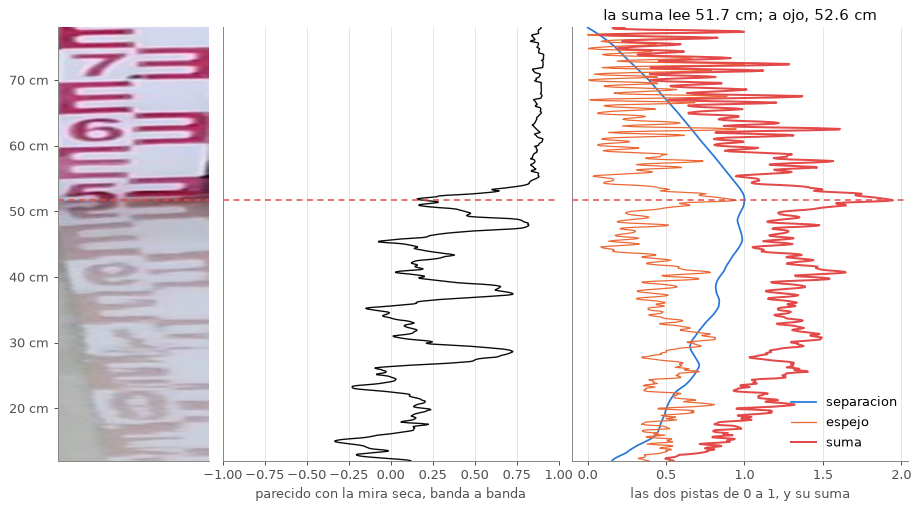

In [16]:
R_ = T.enderezar(gris(leer(FOTO)))
_, _, filas_m, esp_m = espejo(R_)
sep_m = separacion(R_, filas_m)
suma_m = a_01(sep_m) + a_01(esp_m)
fila_m = int(filas_m[np.argmax(suma_m)])
filas_s = np.arange(int(T.fila_de(NIVEL_MAX_AGUA)), int(T.fila_de(NIVEL_MIN_BUSQUEDA)) + 1)
s_m = parecido_con_seca(R_, filas_s)
fig, ax = plt.subplots(1, 3, figsize=(10.5, 5.8), gridspec_kw={"width_ratios": [0.45, 1, 1], "wspace": 0.05}, sharey=True)
ax[0].imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic"); ax[0].set_xticks([])
ax[0].set_yticks([T.fila_de(n) for n in range(20, 81, 10)]); ax[0].set_yticklabels(["%d cm" % n for n in range(20, 81, 10)])
ax[1].plot(s_m, filas_s, color=TINTA, lw=1.1); ax[1].set_xlim(-1, 1); ax[1].set_xlabel("parecido con la mira seca, banda a banda")
ax[2].plot(a_01(sep_m), filas_m, color=AZUL, lw=1.4, label="separacion")
ax[2].plot(a_01(esp_m), filas_m, color=NARANJA, lw=1.0, label="espejo")
ax[2].plot(suma_m, filas_m, color=ROJO, lw=1.6, label="suma")
ax[2].set_xlabel("las dos pistas de 0 a 1, y su suma"); ax[2].legend(frameon=False, loc="lower right")
for a in ax:
    a.axhline(fila_m, color=ROJO, lw=1.2, ls=(0, (4, 3)))
for a in ax[1:]:
    a.grid(axis="x", color=REJILLA, lw=0.8); a.set_axisbelow(True); a.tick_params(axis="y", length=0)
ax[0].set_ylim(T.fila_de(NIVEL_MIN_BUSQUEDA), T.fila_de(NIVEL_MAX_AGUA))
ax[2].set_title("la suma lee %.1f cm; a ojo, %.1f cm" % (T.nivel_de(fila_m), nivel_ojo), color=TINTA)
fig.subplots_adjust(left=0.08, right=0.98, top=0.93, bottom=0.1)

**Lo que queda por resolver.** La comparacion con la mira seca es fila a fila, y la camara se mueve: cambio 2.

## 3.2 Cambio 2: el registro

**El fallo.** Comparar fila a fila exige que las filas coincidan, y la camara se mueve un poco. Aqui 1 cm son 9 filas y los dientes de las E miden unas 9: con 3 filas de desajuste la mira seca deja de parecerse a la foto seca, y la separacion ve agua donde no la hay.

**Que se agrega.** La parte de la mira que nunca se moja, por encima de 78 cm, hace de regla: se busca en cada foto con `cv2.matchTemplate` y se desplaza la foto. Da ademas, de dia y de noche, el parecido de la parte seca que usa el cambio 3.

--- antes
+++ despues
@@ -2,2 +2,4 @@
     R = T.enderezar(gris(leer(archivo)))
+    dx, dy, seco = registrar(R)                                 # [v2]
+    R = alinear(R, dx, dy)                                      # [v2]
     fila, parecido = elegir_fila(R)                             # [v2]
@@ -5,3 +7,3 @@
     return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
-            "fila_foto": float(T.a_foto(ANCHO / 2, fila)[1]), "nivel_bruto_cm": nivel,
+            "fila_foto": float(T.a_foto(ANCHO / 2, fila + dy)[1]), "nivel_bruto_cm": nivel,  # [v2]
             "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO)}



Movimiento vertical en las secciones: de -3 a 5 filas. Parecido de la parte seca: mediana 0.79 sin registro, 0.92 con registro
Saltos en las secciones: sin registro 66, con registro 65. Lecturas que cambian mas de 3 cm: 47


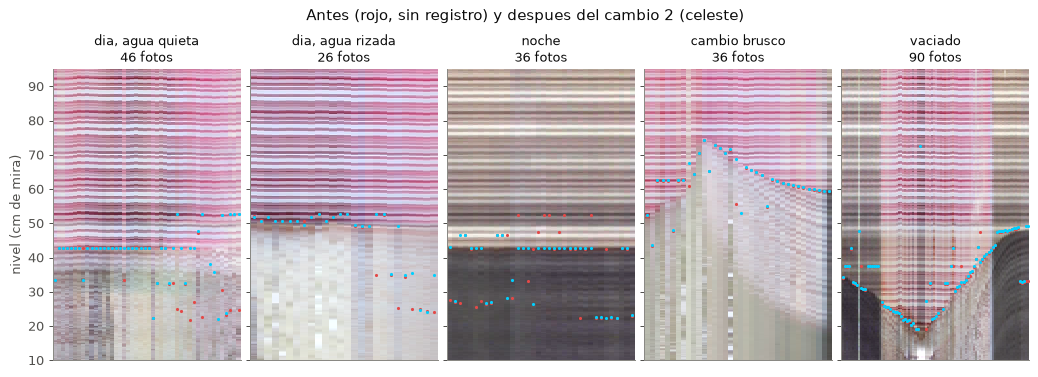

In [17]:
def registrar(R):
    # [v2] cuanto se ha movido la mira: busca la parte que nunca se moja. Devuelve dx, dy (filas) y su parecido con la mira seca
    if SECA is None:
        return 0, 0, 1.0
    r = cv2.matchTemplate(R[:Z1 + MARGEN], PATRON, cv2.TM_CCOEFF_NORMED)
    _, seco, _, (x, y) = cv2.minMaxLoc(r)
    return x - COLUMNAS[0], y - Z0, seco


def alinear(R, dx, dy):
    # [v2] desplaza la foto para que sus filas coincidan con las de la mira seca
    if dx == 0 and dy == 0:
        return R
    return cv2.warpAffine(R, np.float32([[1, 0, -dx], [0, 1, -dy]]), (R.shape[1], R.shape[0]), flags=cv2.INTER_LINEAR)


def medir_foto(archivo):
    R = T.enderezar(gris(leer(archivo)))
    dx, dy, seco = registrar(R)                                 # [v2]
    R = alinear(R, dx, dy)                                      # [v2]
    fila, parecido = elegir_fila(R)                             # [v2]
    nivel = T.nivel_de(fila)
    return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
            "fila_foto": float(T.a_foto(ANCHO / 2, fila + dy)[1]), "nivel_bruto_cm": nivel,  # [v2]
            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO)}


df_c2 = medir_secciones()
print(diff_medir_foto(1, 2))
dibujar_secciones([(df_c1, ROJO, 3), (df_c2, "#00d0ff", 3)], "Antes (rojo, sin registro) y despues del cambio 2 (celeste)")
regs = np.array([registrar(T.enderezar(gris(leer(a)))) for a in fotos_s[::4]])
sin_mover = np.array([parecido_zona_seca(T.enderezar(gris(leer(a)))) for a in fotos_s[::4]])
print("\nMovimiento vertical en las secciones: de %d a %d filas. Parecido de la parte seca: mediana %.2f sin registro, %.2f con registro" % (regs[:, 1].min(), regs[:, 1].max(), np.median(sin_mover), np.median(regs[:, 2])))
print("Saltos en las secciones: sin registro %d, con registro %d. Lecturas que cambian mas de 3 cm: %d" % (df_c1.salto.sum(), df_c2.salto.sum(), ((df_c1.nivel_bruto_cm - df_c2.nivel_bruto_cm).abs() > 3).sum()))

**Lo que queda por resolver.** Las fotos donde no hay mira que leer: cambio 3.

## 3.3 Cambio 3: fotos sin lectura

**El fallo.** La v1 siempre devuelve un numero (2.4).

**Que se agrega.** El mismo parecido del registro hace de control: si la parte que nunca se moja **no se reconoce**, con parecido menor que 0.75, el nivel queda vacio. El parecido tipico es 0.92. Si el agua esta por debajo del minimo, la mejor fila cae por debajo y la regla `bajo_minimo` del notebook 01 hace el resto, sin codigo nuevo.

--- antes
+++ despues
@@ -5,5 +5,6 @@
     fila, parecido = elegir_fila(R)                             # [v2]
-    nivel = T.nivel_de(fila)
+    nivel = T.nivel_de(fila) if seco >= PARECIDO_SECO_MIN else np.nan  # [v2]
     return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
             "fila_foto": float(T.a_foto(ANCHO / 2, fila + dy)[1]), "nivel_bruto_cm": nivel,  # [v2]
-            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO)}
+            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO),  # [v2]
+            "dx": dx, "dy": dy, "parecido_seco": seco}  # [v2]



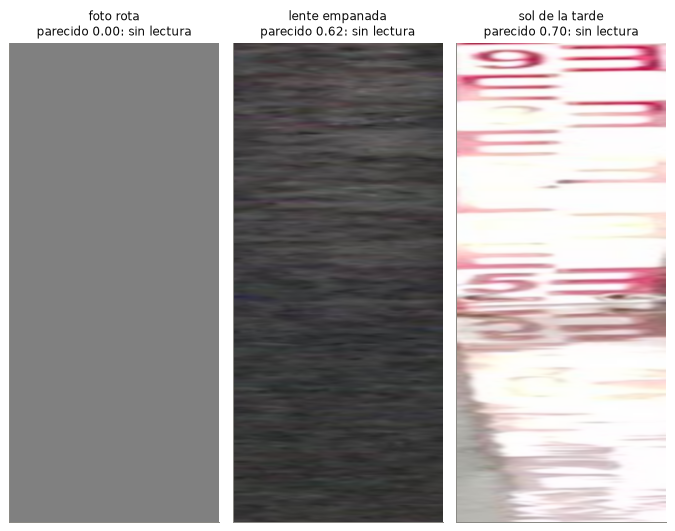

In [18]:
PARECIDO_SECO_MIN = 0.75     # >>> AJUSTABLE <<< [v2] por debajo, la parte que nunca se moja no se reconoce: foto sin lectura


def medir_foto(archivo):
    R = T.enderezar(gris(leer(archivo)))
    dx, dy, seco = registrar(R)                                 # [v2]
    R = alinear(R, dx, dy)                                      # [v2]
    fila, parecido = elegir_fila(R)                             # [v2]
    nivel = T.nivel_de(fila) if seco >= PARECIDO_SECO_MIN else np.nan  # [v2]
    return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
            "fila_foto": float(T.a_foto(ANCHO / 2, fila + dy)[1]), "nivel_bruto_cm": nivel,  # [v2]
            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO),  # [v2]
            "dx": dx, "dy": dy, "parecido_seco": seco}  # [v2]


print(diff_medir_foto(2, 3))
print()
fig, ax = plt.subplots(1, 3, figsize=(7.6, 6))
for a, (nombre, archivo) in zip(ax, CASOS_MALOS):
    r_ = medir_foto(archivo)
    a.imshow(rgb(T.enderezar(leer(archivo))), extent=[0, ANCHO, alto_total, 0], aspect="auto", interpolation="bicubic")
    if np.isfinite(r_["nivel_bruto_cm"]):
        a.axhline(T.fila_de(r_["nivel_bruto_cm"]) + r_["dy"], color=ROJO, lw=1.6)
    a.set_ylim(T.fila_de(10), 0); a.set_xticks([]); a.set_yticks([])
    texto = "sin lectura" if np.isnan(r_["nivel_bruto_cm"]) else "lee %.0f cm" % r_["nivel_bruto_cm"]
    a.set_title("%s\nparecido %.2f: %s" % (nombre, r_["parecido_seco"], texto), fontsize=9.5, color=TINTA)
plt.tight_layout()

## 3.4 Comprobacion: las lineas exactas que cambiaron

Se calcula comparando este notebook con el notebook 01. El diff total de `medir_foto` es la unica modificacion de una funcion que ya existia.

In [19]:
defs_02 = definiciones(NB_02)
versiones_mf = [f for n, f in defs_02 if n == "medir_foto"]
ULTIMA = {}
for n, f in defs_02:
    ULTIMA[n] = f
existentes = {n for n, _ in defs_01}
nuevas = [n for n in ULTIMA if n not in existentes and any(n == m for m in ["memorizar", "parecido_zona_seca", "parecido_con_seca", "a_01", "separacion", "elegir_fila", "registrar", "alinear"])]

print("=== medir_foto: notebook 01 -> v2 ===")
diff_total = list(difflib.ndiff(primera_01["medir_foto"].splitlines(), versiones_mf[-1].splitlines()))
quitadas = [l[2:] for l in diff_total if l.startswith("- ")]
agregadas = [l[2:] for l in diff_total if l.startswith("+ ")]
print("\n".join(difflib.unified_diff(primera_01["medir_foto"].splitlines(), versiones_mf[-1].splitlines(), "notebook 01", "v2", lineterm="", n=1)))
print("\nLineas quitadas de medir_foto: %d | lineas agregadas: %d" % (len(quitadas), len(agregadas)))
print("Todas las lineas agregadas o modificadas llevan # [v2], salvo:", [l for l in agregadas if "[v2]" not in l])

print("\n=== Funciones del metodo que no cambian ===")
for n in ["leer", "rgb", "gris", "recta_por", "Tablero", "fila_homografia", "ncc", "ventanas", "curva_espejo", "espejo", "marcar_saltos"]:
    print("%-16s %s" % (n, "identica al notebook 01" if primera_01[n] == ULTIMA[n] else "DISTINTA"))
    assert primera_01[n] == ULTIMA[n]

print("\n=== Funciones nuevas (todo el codigo nuevo del metodo) ===")
total = 0
for n in nuevas:
    lineas = ULTIMA[n].splitlines()
    total += len(lineas)
    print("%-20s %2d lineas | marcada [v2]: %s" % (n, len(lineas), "[v2]" in ULTIMA[n]))
    assert "[v2]" in ULTIMA[n]
print("Total: %d lineas en %d funciones nuevas" % (total, len(nuevas)))

print("\n=== Parametros nuevos ===")
a02 = asignaciones(NB_02)
for n in ["FOTO_SECA", "BANDA_CM", "MARGEN_REGISTRO_CM", "PARECIDO_SECO_MIN"]:
    print("%-20s %s" % (n, a02[n]))

=== medir_foto: notebook 01 -> v2 ===
--- notebook 01
+++ v2
@@ -2,6 +2,9 @@
     R = T.enderezar(gris(leer(archivo)))
-    fila, parecido, _, _ = espejo(R)
-    nivel = T.nivel_de(fila)
+    dx, dy, seco = registrar(R)                                 # [v2]
+    R = alinear(R, dx, dy)                                      # [v2]
+    fila, parecido = elegir_fila(R)                             # [v2]
+    nivel = T.nivel_de(fila) if seco >= PARECIDO_SECO_MIN else np.nan  # [v2]
     return {"archivo": archivo, "hora": hora_de(archivo), "fila_tablero": fila,
-            "fila_foto": float(T.a_foto(ANCHO / 2, fila)[1]), "nivel_bruto_cm": nivel,
-            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO)}
+            "fila_foto": float(T.a_foto(ANCHO / 2, fila + dy)[1]), "nivel_bruto_cm": nivel,  # [v2]
+            "parecido": parecido, "bajo_minimo": bool(nivel < NIVEL_MINIMO),  # [v2]
+            "dx": dx, "dy": dy, "parecido_seco": seco}  # [v2]

Lineas quitadas de 

**Como se fijo la regla, y control a ojo.** Esta regla no se eligio por su acierto en este lago, sino para que funcione **con los mismos valores en las dos camaras**, este lago y Meguro, sin umbrales por camara. Se fijo antes de comparar con la referencia, con una sola correccion: sin el peso por tamano, la separacion se iba al fondo del rango, donde la foto seca tambien tiene agua. Eso se vio en 4 fotos revisadas a ojo, sin la referencia. Ninguno de sus valores se probo contra la referencia.

La tabla de abajo es solo informativa: compara la v1 y la v2 con una lectura a ojo de 70 fotos repartidas por la serie (~1 cm), que **no es la referencia**.

In [20]:
# Lectura a ojo de la linea de agua (cm de mira), +-1 cm. NO es la referencia: solo sirve para elegir sin abrirla
CONTROL_OJO = {
    "dia": {"P23052705262410": 42.8, "P23052812262310": 42.5, "P23052919262210": 42.5, "P23053112111910": 42.5,
        "P23060205262410": 46.2, "P23060312262310": 44.8, "P23060507562110": 44.7, "P23060615261810": 50.7,
        "P23060808111610": 46.4, "P23060915262410": 47.6, "P23061107562110": 49.7, "P23061214411910": 47.2,
        "P23061407111810": 48.5, "P23061514111610": 48.6, "P23061706562310": 48.8, "P23061813562210": 43.8,
        "P23062107411810": 48.2, "P23062306262310": 47.6, "P23062413262210": 37.1, "P23062711561810": 46.3,
        "P23062818411610": 47.3, "P23070318262010": 52.0, "P23070610561710": 52.6},
    "noche": {"P23052700112410": 42.4, "P23052803412310": 42.4, "P23052922262210": 42.4, "P23053102412010": 42.4,
        "P23060120411710": 46.5, "P23060300562310": 44.8, "P23060500262110": 44.8, "P23060604411910": 45.2,
        "P23060802111610": 46.2, "P23060920412310": 48.0, "P23061100412210": 50.0, "P23061204262110": 48.0,
        "P23061323261810": 48.1, "P23061503411610": 48.1, "P23061621562410": 48.7, "P23061801412310": 46.4,
        "P23062020111910": 48.2, "P23062123561810": 48.0, "P23062323562210": 42.1, "P23062703411810": 46.3,
        "P23062821561610": 46.9, "P23070122562210": 50.3, "P23070304562010": 52.8, "P23070605111610": 51.7},
    "vaciado": {"P23061900112110": 34.8, "P23061904262110": 29.0, "P23061906562010": 24.5, "P23061909262010": 20.2,
        "P23061911412010": 19.5, "P23061913412110": 25.3, "P23061915412110": 30.9, "P23061917412010": 37.6,
        "P23061919412010": 43.1, "P23061921412010": 47.0, "P23061923561910": 48.0},
    "crecida": {"P23070210112210": 65.0, "P23070211262210": 61.3, "P23061713562210": 61.5, "P23070412261810": 57.4,
        "P23070413261910": 65.7, "P23070413561910": 74.7, "P23070414111910": 74.7, "P23070414411910": 71.0,
        "P23070415261910": 68.3, "P23070416261910": 65.0, "P23060107111810": 58.0, "P23070421111910": 58.0},
}


def nivel_v1(R):
    return T.nivel_de(espejo(R)[0])


def nivel_v2(R):
    dx, dy, s = registrar(R)
    return T.nivel_de(elegir_fila(alinear(R, dx, dy))[0])


def ruta_de(nombre):
    return "20%s/images/%s.jpg" % (nombre[1:7], nombre)


def evaluar(item):
    g, nombre, ojo = item
    R_ = T.enderezar(gris(leer(ruta_de(nombre))))
    return g, nivel_v1(R_) - ojo, nivel_v2(R_) - ojo


items = [(g, n, v) for g, d in CONTROL_OJO.items() for n, v in d.items()]
with ThreadPoolExecutor(8) as ex:
    res_ojo = pd.DataFrame(list(ex.map(evaluar, items)), columns=["grupo", "v1", "v2"])
res_ojo.groupby("grupo", sort=False).agg(fotos=("v1", "size"), v1_a_menos_de_2_cm=("v1", lambda e: int((e.abs() <= 2).sum())), v2_a_menos_de_2_cm=("v2", lambda e: int((e.abs() <= 2).sum())),
                                         v2_error_mediano_cm=("v2", "median")).round(1)

,fotos,v1_a_menos_de_2_cm,v2_a_menos_de_2_cm,v2_error_mediano_cm
grupo,,,,
dia,23,0,14,-0.1
noche,24,0,13,0.8
vaciado,11,0,8,1.1
crecida,12,0,7,-0.8


# 4. Resultados en China

## 4.1 La v2 en las secciones

**Todos los parametros quedan congelados aqui**, antes de abrir la referencia. Las lecturas se guardan en `salidas/02_niveles_secciones.csv`.

,fotos,sin_lectura,bajo_minimo,saltos,parecido_seco,dy_mediano
seccion,,,,,,
"dia, agua quieta",46,0,1,13,0.94,1.0
noche,36,0,0,13,0.89,2.0
"dia, agua rizada",26,0,0,8,0.96,1.0
vaciado,90,0,6,22,0.92,2.0
cambio brusco,36,0,0,9,0.92,1.0


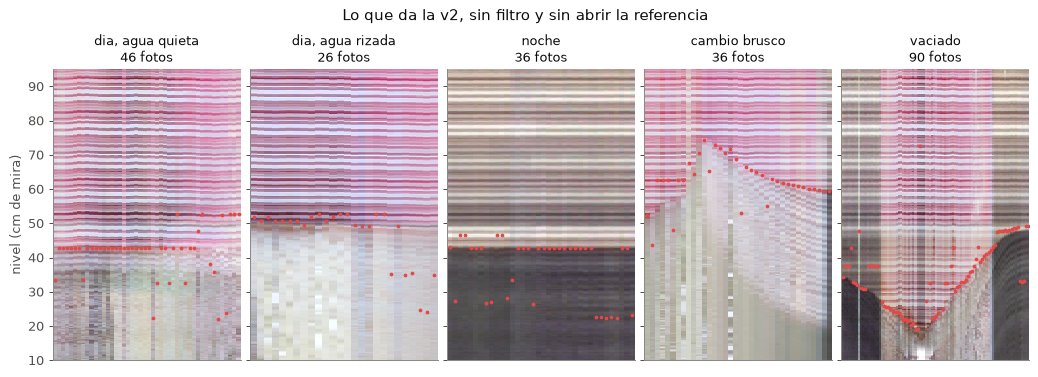

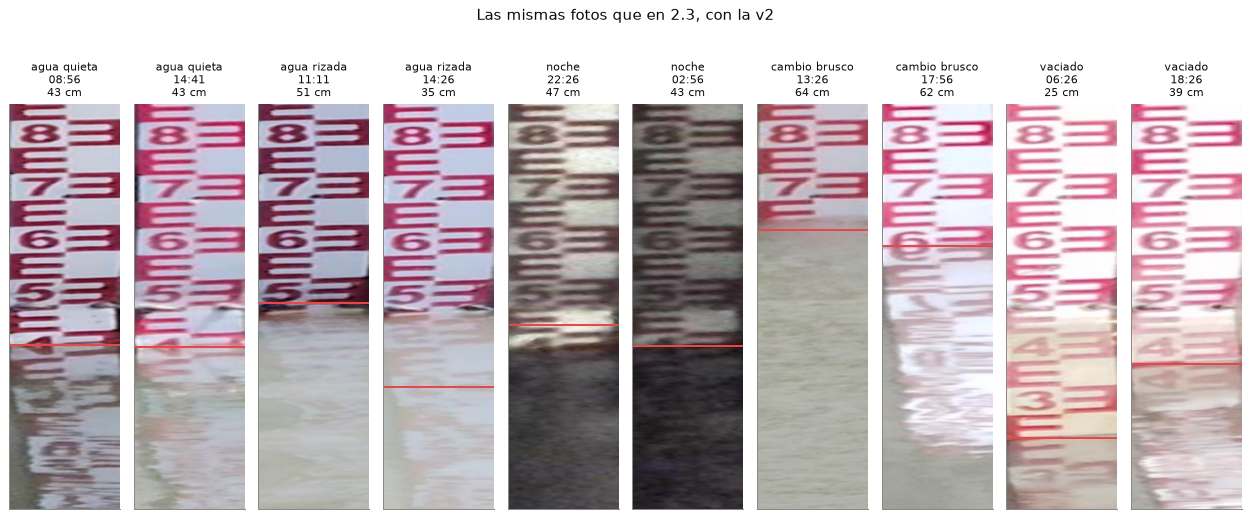

In [21]:
df_v2 = medir_secciones()
df_v2["nivel_v1_cm"] = df_v1.set_index("archivo").nivel_bruto_cm.reindex(df_v2.archivo).values
CSV_SECCIONES = os.path.join(SALIDAS, "02_niveles_secciones.csv")
df_v2.to_csv(CSV_SECCIONES, index=False, float_format="%.4f")
dibujar_secciones([(df_v2, ROJO, 4)], "Lo que da la v2, sin filtro y sin abrir la referencia")
dibujar_ejemplos(df_v2, titulo="Las mismas fotos que en 2.3, con la v2")
df_v2.groupby("seccion", sort=False).agg(fotos=("archivo", "size"), sin_lectura=("nivel_bruto_cm", lambda s: int(s.isna().sum())), bajo_minimo=("bajo_minimo", "sum"),
                                         saltos=("salto", "sum"), parecido_seco=("parecido_seco", "median"), dy_mediano=("dy", "median")).round(2)

## 4.2 Tabla principal: v1 y v2 por seccion, frente a la lectura manual

Aqui se abre, **una sola vez**, la referencia. **Numeros de las secciones, no de la serie completa.**

Lo unico que se estima con ella es el cero: la lectura manual es una cota, no cm de mira, asi que a cada version se le suma **una sola constante**, la mediana de la diferencia en todas sus fotos de las secciones. No se reajusta nada despues de verla: **tras abrirla por primera vez, solo cambiaron los textos, la presentacion de las tablas y la grafica; el metodo y sus parametros, no.** **No es una prueba del todo a ciegas:** los parametros se eligieron sin abrir esta referencia, pero ya se conocian resultados previos de esta camara. Ademas, esta referencia ya se habia abierto con una version anterior de este notebook, guardada en `anteriores/`.

La fila "v1, cero de la v2" esta porque el cero es una propiedad de la mira y de la cota, no del algoritmo: es la que dice si la v1 mide de verdad.

Con lectura manual: 173 de 234 fotos de las secciones
Cero estimado con la referencia (secciones): v2 110.00 cm | v1 80.42 cm


fotos  error abs. medio (cm)  \
seccion             version                                           
dia, agua quieta    v1, su cero           12                   4.52   
                    v1, cero de la v2     12                  29.01   
                    v2                    12                   7.61   
dia, agua rizada    v1, su cero           24                  23.66   
                    v1, cero de la v2     24                  22.91   
                    v2                    26                   5.13   
noche               v1, su cero            9                  17.67   
                    v1, cero de la v2      9                  11.92   
                    v2                     9                   9.14   
cambio brusco       v1, su cero           30                  30.06   
                    v1, cero de la v2     30                  16.99   
                    v2                    36                   2.83   
vaciado             v1, su cero           81                  14.36   
                    v1, cero de la v2     81                  41.28   
                    v2                    84                   3.33   
todas las secciones v1, su cero          156                  18.24   
                    v1, cero de la v2    156                  31.15   
                    v2                   167                   4.12   

                                       sesgo (cm)  max abs. (cm)  % en +-2 cm  \
seccion             version                                                     
dia, agua quieta    v1, su cero             -4.15          51.03        91.67   
                    v1, cero de la v2       25.43          30.17         0.00   
                    v2                      -4.18          20.90        41.67   
dia, agua rizada    v1, su cero            -23.66          55.60         0.00   
                    v1, cero de la v2        5.91          26.02         0.00   
                    v2                      -2.61          24.20        46.15   
noche               v1, su cero            -17.66          20.03        11.11   
                    v1, cero de la v2       11.92          29.63         0.00   
                    v2                      -9.11          20.26        44.44   
cambio brusco       v1, su cero            -30.06          78.33         0.00   
                    v1, cero de la v2       -0.48          48.76         3.33   
                    v2                      -0.73          14.91        63.89   
vaciado             v1, su cero             10.53          56.78         2.47   
                    v1, cero de la v2       40.11          54.64         0.00   
                    v2                       1.97          54.44        70.24   
todas las secciones v1, su cero             -5.29          78.33         8.97   
                    v1, cero de la v2       24.29          54.64         0.64   
                    v2                      -0.36          54.44        61.68   

                                       % en +-5 cm  
seccion             version                         
dia, agua quieta    v1, su cero              91.67  
                    v1, cero de la v2         0.00  
                    v2                       41.67  
dia, agua rizada    v1, su cero               0.00  
                    v1, cero de la v2         0.00  
                    v2                       76.92  
noche               v1, su cero              11.11  
                    v1, cero de la v2         0.00  
                    v2                       44.44  
cambio brusco       v1, su cero               3.33  
                    v1, cero de la v2         6.67  
                    v2                       75.00  
vaciado             v1, su cero              14.81  
                    v1, cero de la v2         0.00  
                    v2                       78.57  
todas las secciones v1, su cero              16.03  
                    v1, cero de la v2      

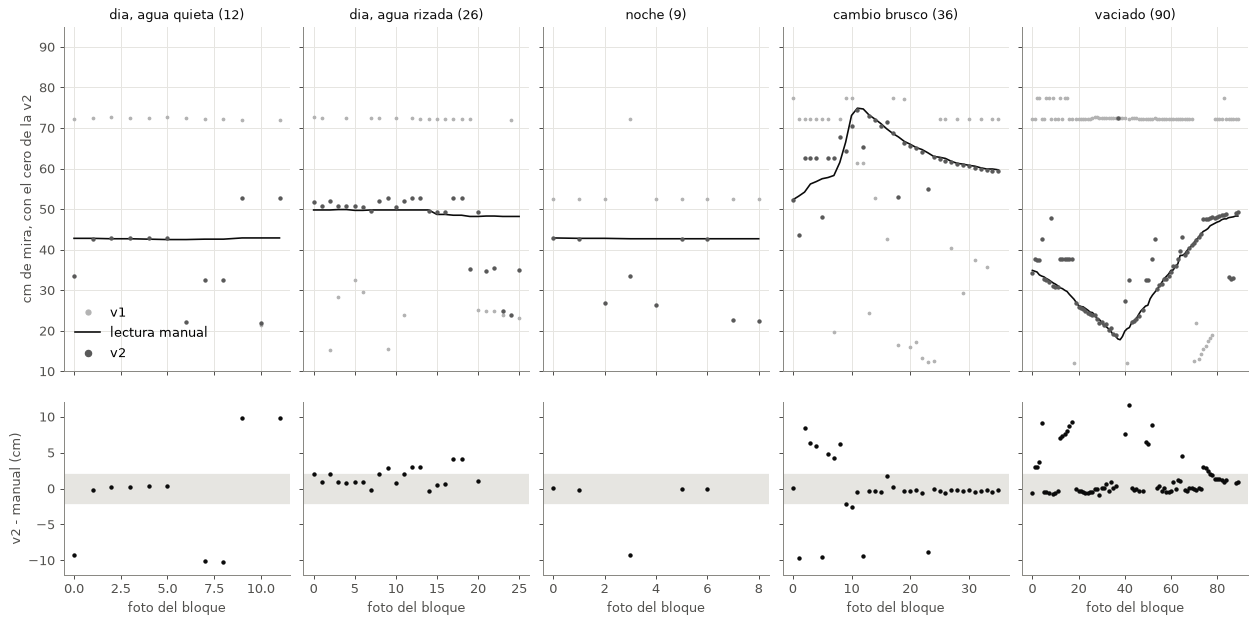

In [22]:
ref = pd.read_excel(EXCEL_REFERENCIA).iloc[1:]
ref = pd.DataFrame({"nombre": ref["Image_name"], "ref_cm": pd.to_numeric(ref["Gauge water level (cm)"])})


def resumen(e):
    e = e.dropna()
    return {"fotos": len(e), "error abs. medio (cm)": e.abs().mean(), "sesgo (cm)": e.mean(), "max abs. (cm)": e.abs().max(),
            "% en +-2 cm": 100 * (e.abs() <= 2).mean(), "% en +-5 cm": 100 * (e.abs() <= 5).mean()}


comp = df_v2.assign(nombre=df_v2.archivo.str.split("/").str[-1]).merge(ref, on="nombre", how="inner")
ok_v2 = comp.nivel_bruto_cm.notna() & ~comp.bajo_minimo.astype(bool)
ok_v1 = comp.nivel_v1_cm >= NIVEL_MINIMO
DATUM_V2 = float((comp.ref_cm - comp.nivel_bruto_cm)[ok_v2].median())
DATUM_V1 = float((comp.ref_cm - comp.nivel_v1_cm)[ok_v1].median())
comp["error_v2"] = (comp.nivel_bruto_cm + DATUM_V2 - comp.ref_cm).round(6)
comp["error_v1"] = (comp.nivel_v1_cm + DATUM_V1 - comp.ref_cm).round(6)
comp["error_v1_cero_v2"] = (comp.nivel_v1_cm + DATUM_V2 - comp.ref_cm).round(6)
print("Con lectura manual: %d de %d fotos de las secciones" % (len(comp), len(df_v2)))
print("Cero estimado con la referencia (secciones): v2 %.2f cm | v1 %.2f cm" % (DATUM_V2, DATUM_V1))
filas_t = []
for s in list(SECCIONES) + ["todas las secciones"]:
    m_s = (comp.seccion == s) if s in SECCIONES else pd.Series(True, index=comp.index)
    for version, ok, col in [("v1, su cero", ok_v1, "error_v1"), ("v1, cero de la v2", ok_v1, "error_v1_cero_v2"), ("v2", ok_v2, "error_v2")]:
        filas_t.append({"seccion": s, "version": version, **resumen(comp[col][ok & m_s])})
tabla_secciones = pd.DataFrame(filas_t).set_index(["seccion", "version"]).round(2)
tabla_secciones["fotos"] = tabla_secciones["fotos"].astype(int)
tabla_secciones.to_csv(os.path.join(SALIDAS, "02_resultados_por_seccion.csv"))

fig, ax = plt.subplots(2, len(SECCIONES), figsize=(14, 7), sharey="row", sharex="col", gridspec_kw={"height_ratios": [2, 1], "wspace": 0.06})
for j, s in enumerate(SECCIONES):
    m_j = comp.seccion == s
    c = comp[m_j]
    x = np.arange(len(c))
    ok_j = ok_v2[m_j].values
    ax[0, j].plot(x, c.nivel_v1_cm, ".", ms=4, color="0.7", label="v1")
    ax[0, j].plot(x, c.ref_cm - DATUM_V2, "-", lw=1.3, color=TINTA, label="lectura manual")
    ax[0, j].plot(x[ok_j], c.nivel_bruto_cm[ok_j], "o", ms=2.5, color="0.35", label="v2")
    ax[0, j].set_title("%s (%d)" % (s, len(c)), fontsize=10, color=TINTA); ax[0, j].grid(color=REJILLA, lw=0.8); ax[0, j].set_axisbelow(True)
    ax[1, j].axhspan(-2, 2, color=REJILLA, zorder=0); ax[1, j].plot(x[ok_j], c.error_v2[ok_j], "o", ms=2.5, color=TINTA)
    ax[1, j].set_ylim(-12, 12); ax[1, j].set_xlabel("foto del bloque")
ax[0, 0].set_ylabel("cm de mira, con el cero de la v2"); ax[1, 0].set_ylabel("v2 - manual (cm)"); ax[0, 0].legend(frameon=False, markerscale=2, loc="lower left")
ax[0, 0].set_ylim(10, 95)
fig.subplots_adjust(left=0.05, right=0.99, top=0.95, bottom=0.08, hspace=0.12)
plt.savefig(os.path.join(SALIDAS, "02_nivel.png"), dpi=130, facecolor="white")
tabla_secciones

**Lectura de la tabla, tal cual, sin reajustar nada.**

- **La v2 mejora las cinco condiciones frente a la v1, pero no por igual:** cambio brusco 2.83 cm, vaciado 3.33 cm, agua rizada 5.13 cm, agua quieta 7.61 cm y noche 9.14 cm.
- **Donde falla, el reflejo es debil o enganoso.** Con agua muy quieta de dia, el reflejo de la mira blanca se parece a la mira seca y la separacion corta unos cm por debajo del agua, mientras el espejo se engana mas arriba, y la suma cae entre los dos: en una foto revisada a ojo lee 22 cm con el agua en ~42 cm. De noche y con agua rizada casi no hay reflejo, y lo mas probable es que el espejo se engane con las E secas y arrastre la suma; esto no se comprobo foto a foto.
- **No hay que fiarse de las filas "v1, su cero".** El cero de la v1 sale de sus propias lecturas falsas (80.42 cm frente a 110.00 cm). En "dia, agua quieta" lee casi siempre lo mismo, sobre la mira seca, y como el agua apenas se mueve, ese cero absorbe el error: por eso sale 91.7 %. Con el cero de la v2 se ve que no mide.
- **Pocas fotos en dos secciones:** la lectura manual es horaria esos dias, y quedan 12 de 46 fotos en "dia, agua quieta" y 9 de 36 en "noche". Las secciones se fijaron antes de saberlo y no se cambiaron.

## 4.3 Validacion: la v2 en la serie completa

**Numeros de las 3315 fotos, no de las secciones.** Es una sola pasada, con los parametros congelados. Para no releer las fotos 4K se usa `salidas/02_cache_tiras.*`, la mira ya enderezada de cada foto; si no existe, se regenera desde las fotos. El cache se comprueba contra la configuracion, y `medir_foto` es la misma: solo se le da la tira ya enderezada.

Serie completa medida otra vez
Serie completa: 3315 fotos | con lectura 3297 | sin lectura 5 | bajo el minimo 13 | saltos 486
Cero estimado en la serie completa: 109.94 cm (en las secciones: 110.00 cm)
Comprobacion del cache en las fotos de las secciones: 230 de 234 lecturas iguales; 3 difieren mas de 0.5 cm; diferencia maxima 24.7 cm


,fotos,error abs. medio (cm),sesgo (cm),max abs. (cm),% en +-2 cm,% en +-5 cm
"v2, serie completa",2680,2.91,-1.04,29.72,73.62,80.19
de dia (5 a 20 h),1698,3.04,-1.40,29.72,71.85,77.33
de noche (20 a 5 h),982,2.69,-0.43,20.32,76.68,85.13
sin los saltos (informativo),2321,2.14,-0.75,20.33,82.16,87.20


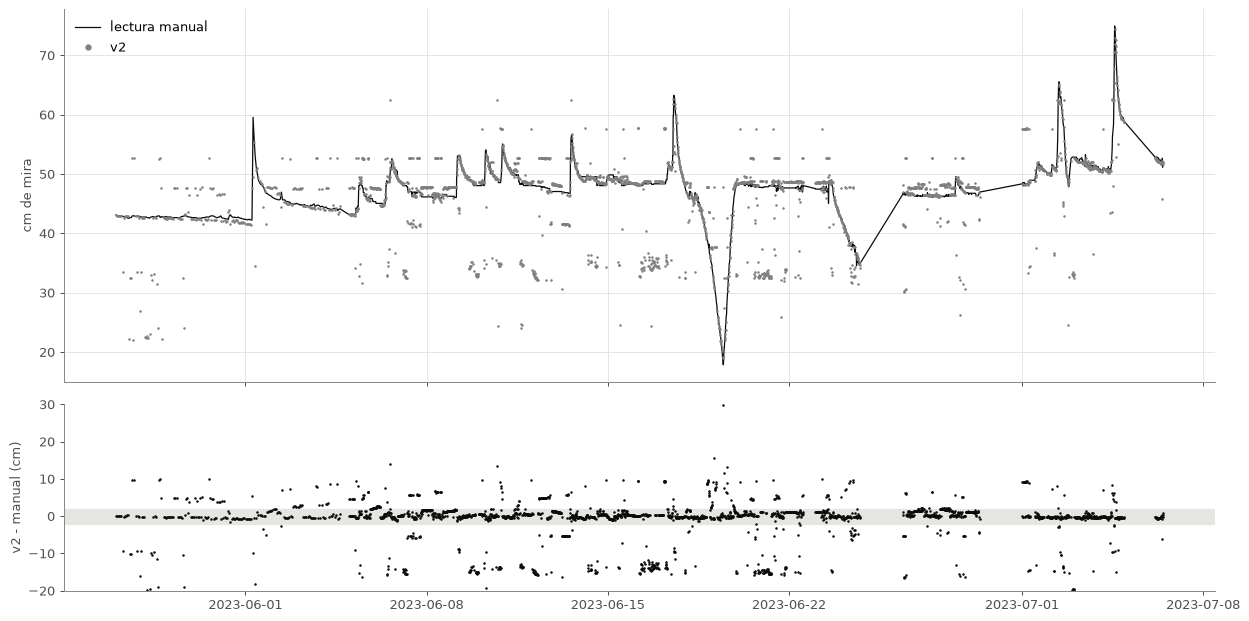

In [23]:
CACHE_NPY, CACHE_JSON = os.path.join(SALIDAS, "02_cache_tiras.npy"), os.path.join(SALIDAS, "02_cache_tiras.json")
CSV_COMPLETA = os.path.join(SALIDAS, "02_niveles_medidos.csv")


class TableroYaEnderezado(Tablero):
    # la misma clase, para tiras que ya vienen enderezadas
    def enderezar(self, img):
        return img


def crear_cache():
    salida = np.lib.format.open_memmap(CACHE_NPY, mode="w+", dtype=np.uint8, shape=(len(fotos), T.tam[1], T.tam[0], 3))

    def una(i):
        salida[i] = T.enderezar(leer(fotos[i]))
    with ThreadPoolExecutor(8) as ex:
        list(ex.map(una, range(len(fotos))))
    salida.flush()
    json.dump({"archivos": fotos, "PX": PX_POR_CM, "ANCHO": ANCHO, "EXTRA": EXTRA_CM, "matriz": T.M.tolist()}, open(CACHE_JSON, "w"))


def medir_serie_completa():
    global T, leer
    if not (os.path.exists(CACHE_NPY) and os.path.exists(CACHE_JSON)):
        crear_cache()
    meta = json.load(open(CACHE_JSON))
    assert (meta["PX"], meta["ANCHO"], meta["EXTRA"]) == (PX_POR_CM, ANCHO, EXTRA_CM) and np.allclose(meta["matriz"], T.M), "el cache no es de esta configuracion"
    tiras = np.load(CACHE_NPY, mmap_mode="r")
    indice = {a.replace("\\", "/"): i for i, a in enumerate(meta["archivos"])}
    T_real, leer_real = T, leer
    T = TableroYaEnderezado(SUP_IZQ, SUP_DER, INF_DER, INF_IZQ, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
    leer = lambda a: np.asarray(tiras[indice[a]])
    try:
        with ThreadPoolExecutor(8) as ex:
            d = pd.DataFrame(list(ex.map(medir_foto, fotos))).sort_values("hora").reset_index(drop=True)
    finally:
        T, leer = T_real, leer_real
    d["nivel_m"] = np.where(d.bajo_minimo, np.nan, d.nivel_bruto_cm / 100)
    d["salto"] = marcar_saltos(d.nivel_bruto_cm.values)
    d.to_csv(CSV_COMPLETA, index=False, float_format="%.4f")
    return d


if SOLO_SECCIONES and os.path.exists(CSV_COMPLETA):
    serie = pd.read_csv(CSV_COMPLETA, parse_dates=["hora"])
    print("Serie completa leida de %s (SOLO_SECCIONES = True)" % CSV_COMPLETA)
else:
    serie = medir_serie_completa()
    print("Serie completa medida otra vez")

d_ref = serie.assign(nombre=serie.archivo.str.split("/").str[-1]).merge(ref, on="nombre", how="inner")
ok_c = d_ref.nivel_bruto_cm.notna() & ~d_ref.bajo_minimo.astype(bool)
DATUM_C = float((d_ref.ref_cm - d_ref.nivel_bruto_cm)[ok_c].median())
d_ref["error_v2"] = (d_ref.nivel_bruto_cm + DATUM_C - d_ref.ref_cm).round(6)
noche = (d_ref.hora.dt.hour >= 20) | (d_ref.hora.dt.hour < 5)
tabla_completa = pd.DataFrame({"v2, serie completa": resumen(d_ref.error_v2[ok_c]), "de dia (5 a 20 h)": resumen(d_ref.error_v2[ok_c & ~noche]), "de noche (20 a 5 h)": resumen(d_ref.error_v2[ok_c & noche]),
                               "sin los saltos (informativo)": resumen(d_ref.error_v2[ok_c & ~d_ref.salto.astype(bool)])}).T.round(2)
tabla_completa["fotos"] = tabla_completa["fotos"].astype(int)
print("Serie completa: %d fotos | con lectura %d | sin lectura %d | bajo el minimo %d | saltos %d" % (len(serie), (serie.nivel_bruto_cm.notna() & ~serie.bajo_minimo.astype(bool)).sum(), serie.nivel_bruto_cm.isna().sum(), serie.bajo_minimo.astype(bool).sum(), serie.salto.astype(bool).sum()))
print("Cero estimado en la serie completa: %.2f cm (en las secciones: %.2f cm)" % (DATUM_C, DATUM_V2))
cruce = serie.merge(df_v2[["archivo", "nivel_bruto_cm"]], on="archivo", suffixes=("_cache", "_fotos"))
dif_c = (cruce.nivel_bruto_cm_cache - cruce.nivel_bruto_cm_fotos).abs()
print("Comprobacion del cache en las fotos de las secciones: %d de %d lecturas iguales; %d difieren mas de 0.5 cm; diferencia maxima %.1f cm" % ((dif_c < 1e-3).sum(), len(cruce), (dif_c > 0.5).sum(), dif_c.max()))

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(d_ref.hora, d_ref.ref_cm - DATUM_C, "-", lw=1, color=TINTA, label="lectura manual")
ax[0].plot(d_ref.hora[ok_c], d_ref.nivel_bruto_cm[ok_c], ".", ms=2, color="0.5", label="v2")
ax[0].set_ylabel("cm de mira"); ax[0].legend(frameon=False, markerscale=4, loc="upper left"); ax[0].grid(color=REJILLA, lw=0.8); ax[0].set_axisbelow(True)
ax[1].axhspan(-2, 2, color=REJILLA, zorder=0); ax[1].plot(d_ref.hora[ok_c], d_ref.error_v2[ok_c], ".", ms=2, color=TINTA)
ax[1].set_ylim(-20, 30); ax[1].set_ylabel("v2 - manual (cm)")
plt.tight_layout()
tabla_completa

**Lectura de la serie completa, aparte de las secciones.**

- **2.91 cm de error absoluto medio, 73.62 % en +-2 cm y 80.19 % en +-5 cm** en 2680 fotos, sin filtro temporal: 3.04 cm de dia y 2.69 cm de noche.
- **El cero sale casi igual** con las secciones (110.00 cm) y con la serie completa (109.94 cm). El sesgo global es ~0 por construccion, asi que lo que cuenta es la dispersion.
- **531 lecturas con mas de 5 cm de error**, y la peor a 29.7 cm.
- **Fotos sin dar nivel:** 5 sin lectura y 13 bajo el minimo.
- **Cache:** en las 234 fotos de las secciones, 230 lecturas coinciden con las hechas desde las fotos, 3 difieren mas de 0.5 cm y la mayor diferencia es de 24.7 cm. Con dos pistas que compiten, una diferencia minima en la imagen puede cambiar la fila ganadora.

## 4.4 Video

Solo las fotos de las secciones: la camara a la izquierda y la mira de cerca con la linea y el nivel a la derecha. Sale en `salidas/02_video.mp4`, en H.264.

In [24]:
ZOOM = (1850, 1040, 300, 860)      # vista cercana: x, y, ancho, alto
ALTO = 720
ANCHO_CAMARA = 1280
ANCHO_ZOOM = int(round(ZOOM[2] * ALTO / ZOOM[3])) // 2 * 2
ESCALA = ANCHO_CAMARA / 3840.0


def fotograma(img_, f):
    x, y, w, h = ZOOM
    izq = cv2.resize(img_, (ANCHO_CAMARA, ALTO), interpolation=cv2.INTER_AREA)
    cv2.rectangle(izq, (int(x * ESCALA), int(y * ESCALA)), (int((x + w) * ESCALA), int((y + h) * ESCALA)), (0, 220, 255), 2)
    der = cv2.resize(img_[y:y + h, x:x + w], (ANCHO_ZOOM, ALTO), interpolation=cv2.INTER_AREA)
    if np.isnan(f.nivel_bruto_cm):
        texto = "-"
    elif f.bajo_minimo:
        texto = "<= %d cm" % NIVEL_MINIMO
    else:
        fila = int((f.fila_foto - y) * ALTO / h)
        cv2.line(der, (0, fila), (ANCHO_ZOOM, fila), (0, 0, 255), 3, cv2.LINE_AA)
        texto = "%.1f cm" % f.nivel_bruto_cm
    cv2.rectangle(der, (0, ALTO - 70), (ANCHO_ZOOM, ALTO), (0, 0, 0), -1)
    cv2.putText(der, texto, (10, ALTO - 22), cv2.FONT_HERSHEY_SIMPLEX, 1.05, (255, 255, 255), 2, cv2.LINE_AA)
    return cv2.hconcat([izq, der])


FPS, CRF = 8, 26                   # 234 fotos: ~30 s de video
VIDEO = os.path.join(SALIDAS, "02_video.mp4")
vw = escritor_video.abrir(VIDEO, FPS, (ANCHO_CAMARA + ANCHO_ZOOM, ALTO), crf=CRF, preset="veryfast")
filas_v = list(df_v2.itertuples())
with ThreadPoolExecutor(max_workers=8) as ex:
    for i in range(0, len(filas_v), 32):
        tanda = filas_v[i:i + 32]
        for f, img_ in zip(tanda, ex.map(lambda f: leer(f.archivo), tanda)):
            vw.write(fotograma(img_, f))
vw.release()
print("video: %s (%.1f MB, %d fotos)" % (VIDEO, os.path.getsize(VIDEO) / 1e6, len(filas_v)))

video: salidas\02_video.mp4 (10.2 MB, 234 fotos)


# 5. Comprobacion en Meguro

**Requisito:** los cambios no pueden empeorar el primer ejemplo, **con los mismos valores**. Aqui se corre el mismo codigo de la v2 sobre las 53 fotos de Meguro: las funciones se toman del propio notebook, sin copiarlas, y solo cambia la configuracion de la camara, que es la del notebook 01, mas su foto seca, elegida con la misma regla: la de agua mas baja, la de las 17:00. Se compara con `salidas/01_niveles_medidos.csv`, que no se modifica y ya trae el nivel oficial de cada foto.

## 5.1 Resultado con los mismos valores

In [25]:
# Configuracion de Meguro: los valores se leen del propio notebook 01
exec(primera_01["hora_de"])
CARPETA_FOTOS = os.path.join("..", "..", "05_tokio_meguro_suimon", "datos", "capturas")
TEXTO_NIVEL = (430, 15, 960, 95)
PX_POR_CM, ANCHO, EXTRA_CM, VENTANA_CM, COLUMNAS = 2.0, 62, 40.0, 8.0, (3, 59)
NIVEL_SUP, FILA_SUP, NIVEL_INF, FILA_INF = 350.0, 148.0, 150.0, 521.4
NIVEL_MINIMO, NIVEL_MAX_AGUA, NIVEL_MIN_BUSQUEDA = 150.0, 170.0, 144.0
for n, v in [("PX_POR_CM", PX_POR_CM), ("ANCHO", ANCHO), ("EXTRA_CM", EXTRA_CM), ("NIVEL_SUP", NIVEL_SUP), ("FILA_SUP", FILA_SUP), ("NIVEL_INF", NIVEL_INF), ("FILA_INF", FILA_INF),
             ("NIVEL_MINIMO", NIVEL_MINIMO), ("NIVEL_MAX_AGUA", NIVEL_MAX_AGUA), ("NIVEL_MIN_BUSQUEDA", NIVEL_MIN_BUSQUEDA), ("COLUMNAS", COLUMNAS)]:
    assert eval(asignaciones(NB_01)[n]) == v, n          # comprueba contra el notebook 01
x_izq, x_der = recta_por(eval(asignaciones(NB_01)["BORDE_IZQ"])), recta_por(eval(asignaciones(NB_01)["BORDE_DER"]))
SUP_IZQ, SUP_DER = (float(x_izq(FILA_SUP)), FILA_SUP), (float(x_der(FILA_SUP)), FILA_SUP)
INF_DER, INF_IZQ = (float(x_der(FILA_INF)), FILA_INF), (float(x_izq(FILA_INF)), FILA_INF)
T = Tablero(SUP_IZQ, SUP_DER, INF_DER, INF_IZQ, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
H = int(VENTANA_CM * PX_POR_CM)
for n in ["ventanas", "curva_espejo", "espejo"]:     # sus valores por defecto toman los de esta camara; el codigo es el mismo
    exec(ULTIMA[n])
exec(ULTIMA["medir_foto"])                           # la v2

m1 = pd.read_csv(os.path.join("..", "01_meguro_algoritmo_basico", "salidas", "01_niveles_medidos.csv"), parse_dates=["hora"])

FOTO_SECA = "20261020_170000.jpg"                    # la foto de agua mas baja de Meguro
memorizar()
v2_meg = pd.DataFrame([medir_foto(a) for a in m1.archivo])


def metricas_meguro(nivel, bajo):
    e = (nivel - m1.oficial_m * 100).round(6)
    ok = ~pd.Series(bajo).astype(bool) & nivel.notna() & m1.oficial_m.notna()
    return {"fotos con lectura": "%d de %d" % (ok.sum(), len(m1)), **{k: round(v, 2) for k, v in resumen(e[ok]).items() if k != "fotos"}}


cambio = (v2_meg.nivel_bruto_cm - m1.nivel_bruto_cm).abs()
print("Lecturas que cambian: %d de %d (mas de 1 cm: %d; mas de 3 cm: %d) | sin lectura: %d" % ((cambio > 1e-4).sum(), len(m1), (cambio > 1).sum(), (cambio > 3).sum(), v2_meg.nivel_bruto_cm.isna().sum()))
tabla_meguro = pd.DataFrame({"v1 (CSV del notebook 01)": metricas_meguro(m1.nivel_bruto_cm, m1.bajo_minimo), "v2, mismos valores": metricas_meguro(v2_meg.nivel_bruto_cm, v2_meg.bajo_minimo)}).T
tabla_meguro

Lecturas que cambian: 17 de 53 (mas de 1 cm: 2; mas de 3 cm: 1) | sin lectura: 0


,fotos con lectura,error abs. medio (cm),sesgo (cm),max abs. (cm),% en +-2 cm,% en +-5 cm
v1 (CSV del notebook 01),50 de 53,1.11,-0.91,8.0,92.0,98.0
"v2, mismos valores",50 de 53,0.87,-0.77,3.0,96.0,100.0


## 5.2 Foto a foto

In [26]:
foto_a_foto = pd.DataFrame({"hora": m1.hora.dt.strftime("%H:%M"), "oficial_cm": (m1.oficial_m * 100).round(1), "v1_cm": m1.nivel_bruto_cm, "v2_cm": v2_meg.nivel_bruto_cm})
foto_a_foto["v2 - v1"] = (foto_a_foto.v2_cm - foto_a_foto.v1_cm).round(2)
foto_a_foto["error v1"] = (foto_a_foto.v1_cm - foto_a_foto.oficial_cm).round(1)
foto_a_foto["error v2"] = (foto_a_foto.v2_cm - foto_a_foto.oficial_cm).round(1)
foto_a_foto.to_csv(os.path.join(SALIDAS, "02_meguro_foto_a_foto.csv"), index=False)
pd.set_option("display.max_rows", 60)
foto_a_foto

,hora,oficial_cm,v1_cm,v2_cm,v2 - v1,error v1,error v2
0,12:44,154.0,154.5,154.5,0.0,0.5,0.5
1,12:47,155.0,156.5,156.0,-0.5,1.5,1.0
2,12:50,156.0,155.5,155.5,0.0,-0.5,-0.5
3,12:55,157.0,156.0,156.0,0.0,-1.0,-1.0
4,13:00,159.0,157.0,157.0,0.0,-2.0,-2.0
5,13:05,159.0,159.0,158.5,-0.5,0.0,-0.5
6,13:10,159.0,158.5,158.5,0.0,-0.5,-0.5
7,13:15,158.5,158.0,158.0,0.0,-0.5,-0.5
8,13:20,158.0,157.0,157.0,0.0,-1.0,-1.0
9,13:25,158.0,150.0,157.0,7.0,-8.0,-1.0


**Resultado de la comprobacion.**

- **Con los mismos valores se cumple el requisito, y Meguro mejora:** 0.87 cm, sesgo -0.77 cm, 96 % en +-2 cm, 100 % en +-5 cm, 50 de 53 fotos y maximo 3 cm, frente a 1.11 cm, 92 %, 98 % y 8 cm de la v1.
- **Cambian 17 de 53 lecturas**, 2 de ellas mas de 1 cm y 1 mas de 3 cm: la de las 13:25, que pasa de 8 cm a 1 cm de error.
- **Por que funciona aqui:** en Meguro el espejo es la pista fuerte, y la separacion lo protege del parecido falso al pie de la mira.

**Lo que esto significa.** Es la primera version que mejora los dos ejemplos con los mismos valores. En China, en cambio, queda lejos de lo que daba la memoria con umbral de la version anterior.

# 6. Limitaciones

- **Sumar las dos pistas con el mismo peso falla cuando las dos se enganan, cada una en un sitio distinto:** agua muy quieta de dia, noche y agua rizada en China.
- **En China queda peor que la memoria con umbral de la version anterior** (2.91 frente a 0.57 cm en la serie completa), que no servia en Meguro con los mismos valores.
- **La lectura puede saltar entre dos picos:** con dos pistas que compiten, una diferencia minima en la imagen puede cambiar la fila elegida (en el cache, hasta 24.7 cm).
- **Hace falta una foto seca**, de agua baja. Por debajo de su agua (~18 cm) la separacion no ve nada, porque la foto seca tambien tiene agua.
- **El rango se fija mirando la serie entera:** una crecida por encima de 78 cm no se podria leer, y ademas ensuciaria la regla del registro.
- **No es del todo a ciegas.** Se conocian resultados previos de esta camara y de Meguro, esta referencia ya se habia abierto con la version anterior, y hay un cero estimado con la referencia.
- **Pocas fotos con referencia en dos secciones:** 12 en "dia, agua quieta" y 9 en "noche".
- **Configuracion a mano** para cada camara.

Salidas de este notebook, en `salidas/`:

- `02_v1_secciones.csv` y `02_niveles_secciones.csv`: lecturas en las secciones, v1 y v2;
- `02_resultados_por_seccion.csv`: la tabla principal;
- `02_niveles_medidos.csv`: la v2 en la serie completa;
- `02_meguro_foto_a_foto.csv`: la comprobacion en Meguro;
- `02_nivel.png`: la grafica de la seccion 4.2;
- `02_video.mp4`: el video de las secciones;
- `02_cache_tiras.npy` y `.json`: la mira enderezada de cada foto (483 MB); se puede borrar, porque se regenera desde las fotos.